In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# 5p CD4

In [3]:
gut_cdn <- readRDS("../241201_VN_PREDICT2/data/cdn/gut_5p_integrated_cd4_prolif_filt.rds")

## Heatmap marker genes

In [56]:
markers2  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              "CXCR5", "GPR183", 
              "FOXP3", "IKZF2","IL2RA","TNFRSF18","CTLA4",
              "GATA3", "IL13","NEFL","PLP2","IL4", "ZBTB16",'IL5',
              "CCR6", "RORC" ,"IL17A","EOMES","IL17F","CXCR6","IL26",
              "ITGB1","S100A4","S100A6",
                   "IL23R","KLRB1","CCL5", "TBX21", "IFNG",
               "MKI67", "PCNA", "MCM6",
              "FASLG", "CST7","CCL5",'CXCR3',"CCL4",'XCL1','CD177','BATF',
               'IL22','RORA','CXCL13','IL21','GZMB',"GNLY","IL26",'PRF1',
'KLRD1','XCL1','CCL3L1','HLA-DRB5','HLA-DRA','CCL25',"TNF","CD40LG")

avgexp = AverageExpression(gut_cdn, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

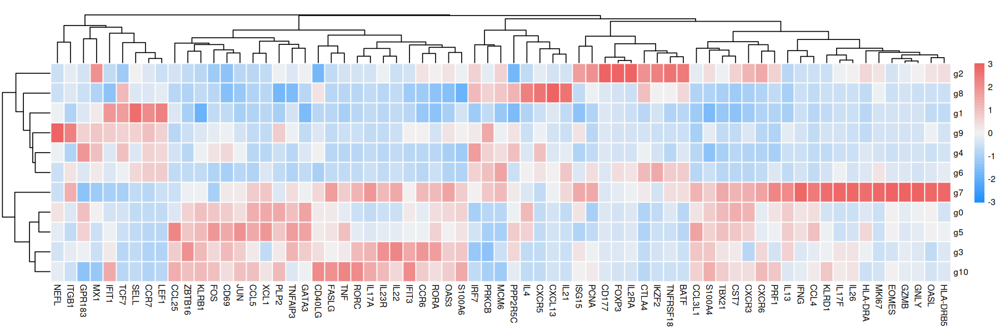

In [57]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [67]:
markers2  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              "CXCR5", "GPR183", 
              "FOXP3", "IKZF2","IL2RA","TNFRSF18","CTLA4",
              "GATA3", "IL13","NEFL","IL4", "ZBTB16",'IL5','KLF2',"KLF3",
              "CCR6", "RORC" ,"IL17A","EOMES","IL17F","CXCR6","IL26",
              "ITGB1","S100A4","S100A6",
                   "IL23R","KLRB1","CCL5", "TBX21", "IFNG",
              "FASLG", "CST7","CCL5",'CXCR3',"CCL4",'XCL1','CD177','BATF',
               'IL22','RORA','CXCL13','IL21','GZMB',"GNLY","IL26",'PRF1',
'KLRD1','XCL1','CCL3L1','HLA-DRB5','HLA-DRA','CCL25',"TNF","CD40LG")

avgexp = AverageExpression(gut_cdn, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

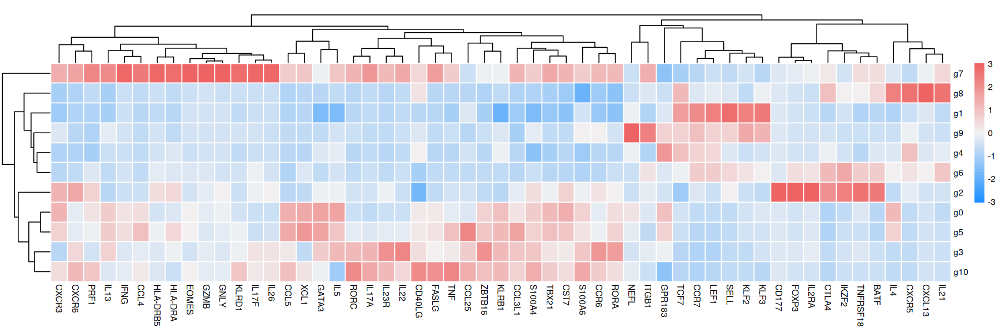

In [68]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [102]:
markers3  <- c('KLF2','SELL',"LEF1",'CCR7',"TCF7",
  'GPR183','ITGB1',"NEFL",
  'BATF','TNFRSF18','IKZF2','CTLA4','IL2RA','FOXP3','CD177',
  'IL21','CXCL13','CXCR5','IL4',
  'RORA','CCR6','S100A6','CST7', 'TBX21', 'S100A4', 'CCL3L1', 'KLRB1', 
  'ZBTB16', 'CCL25', 'TNF', 'FASLG', 'CD40LG', 'IL22', 'IL23R', 'IL17A', 
  'RORC', 'IL5', 'GATA3', 'XCL1', 'CCL5', 'CXCR3', 'CXCR6', 'PRF1', 'IL13', 'IFNG', 'CCL4', 'HLA-DRB5', 'HLA-DRA', 'EOMES', 'GZMB', 'GNLY', 
  'KLRD1', 'IL17F', 'IL26'
 )

avgexp = AverageExpression(gut_cdn, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

In [105]:
mtx_ordered <- t(avgexp$RNA)[c(2,10,5,7,3,9,1,6,4,11,8),]

In [109]:
mtx_ordered2 <- as.matrix(mtx_ordered)[,match(markers3, colnames(mtx_ordered))]
mtx_ordered2

,KLF2,SELL,LEF1,CCR7,TCF7,GPR183,ITGB1,NEFL,BATF,TNFRSF18,⋯,IFNG,CCL4,HLA-DRB5,HLA-DRA,EOMES,GZMB,GNLY,KLRD1,IL17F,IL26
g1,9.3290113,7.61742833,6.4619170,7.0785000,6.8108969,4.013181,0.5909909,0.0120310507,0.6885399,0.01915915,⋯,0.01802438,0.0966652,0.2724409,0.7821456,0.02136629,0.007606033,0.02567232,0.01468868,0.001141434,0.0004225353
g9,6.7873263,2.96082144,3.1687248,4.5879569,4.4613203,5.547786,1.5052999,0.0739521103,1.2629697,0.42711706,⋯,0.12533250,0.1466722,0.3756998,0.8331242,0.01620357,0.009571564,0.05641459,0.03498248,0.017180225,0.0091396399
g4,0.9521329,0.88824202,2.8441184,3.8793189,5.1661908,7.444668,0.6074403,0.0107110052,1.5209878,0.18240488,⋯,0.07419529,0.1590220,0.3652586,0.9971850,0.01227010,0.008304094,0.02521046,0.01329410,0.010522115,0.0028159407
g6,3.4675777,2.86743269,3.4175120,4.1523759,2.8828204,3.952757,0.9371268,0.0024135569,3.3432258,2.05902939,⋯,0.12356974,0.2074729,0.4861199,1.0003465,0.02656951,0.030155296,0.03875721,0.03776899,0.064716051,0.0316605844
g2,0.8678189,1.66349104,0.8509288,1.4257759,0.2150668,3.794870,0.7909567,0.0007264467,6.2392759,4.10028266,⋯,0.10001890,0.3090068,0.7700555,1.4091353,0.01732631,0.116267389,0.22891943,0.02813588,0.063965406,0.1602815066
g8,0.5436351,0.80322257,1.4718430,1.5864984,5.5315037,3.530055,0.7501860,0.0009032855,2.9705867,1.17452746,⋯,0.08093650,0.1201805,0.3552449,0.8787730,0.01113457,0.003598741,0.01566441,0.01994733,0.006659416,0.0009602288
g0,1.3288481,0.17690022,0.4936754,0.5362619,1.9563530,6.000160,0.7586000,0.0184475896,0.8281746,0.71607613,⋯,0.76055823,1.3490163,0.4015396,1.0194500,0.04891774,0.070748001,0.17768505,0.03972759,0.004510929,0.0112352410
g5,1.0974748,0.11692470,0.3794923,0.3690927,1.7982927,5.448623,0.6781588,0.0091219644,0.8577073,0.50735115,⋯,0.84443378,1.9294442,0.5534729,1.4061084,0.04979350,0.060641877,0.15214551,0.07419839,0.008098591,0.0413472363
g3,0.5302948,0.04135651,0.1662201,0.2447020,1.2399440,4.415545,0.8007439,0.0049586693,1.1942208,0.67555448,⋯,0.20268719,0.7225714,0.4478638,1.1197625,0.02230743,0.076565229,0.09244853,0.07767620,0.106894103,0.2409890699
g10,0.6015342,0.08506835,0.2867635,0.2264664,1.2647778,2.242205,0.6977962,0.0097201697,1.2288467,0.49209435,⋯,0.30798718,1.0657302,0.4183342,0.9153405,0.04810724,0.090642126,0.16032760,0.17704021,0.097531289,0.2440902616


In [112]:
dir.create("figures/characterization_CD4CTL/")

In [113]:
pheatmap::pheatmap(mtx_ordered2, main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers.pdf",
                  width = 12, height = 4)

## Markers previously characterized CD4 CTL

In [8]:

cd4_ctl_markers <- c(
    # Cytotoxic machinery
  "NKG7", "GZMA", "GZMB", "GZMK", "PRF1",
  "GNLY", "FASLG", "LAMP1",

  # Th1 / inflammatory phenotype
  "IFNG", "TNF", "TBX21", "EOMES",

  # NKG2D-associated phenotype
  "KLRK1", "HCST", "IL15RA",

  # Th17-associated phenotype
  "KLRB1", "CCR6", "IL23R", "RORC",
  "IL17A", "IL22",

  # Tissue residency / trafficking
  "ITGAE", "CD69", "CCR5", "CX3CR1",

  # Differentiation / memory
  "CD28", "CD27", "CCR7", "IL7R"
)


In [9]:
avgexp = AverageExpression(gut_cdn, features = cd4_ctl_markers, group.by = "seurat_clusters",
                          assay = "RNA")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `seurat_clusters` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


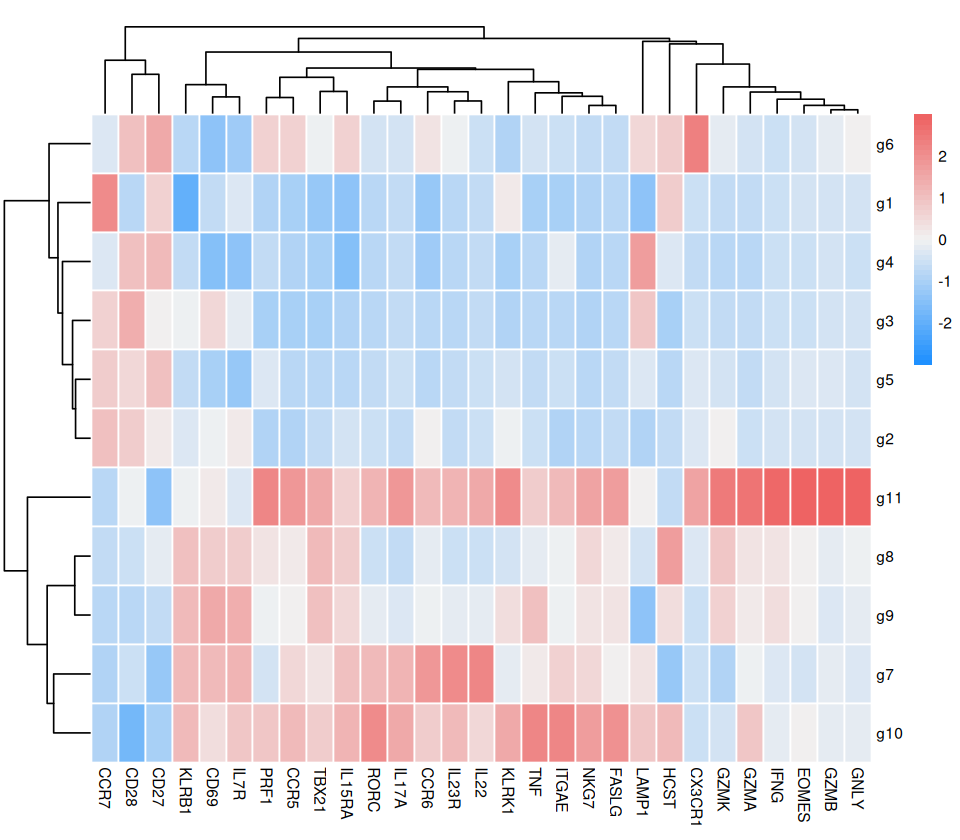

In [15]:
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 12, height = 4)

In [16]:
dir.create("figures/characterization_CD4CTL/")

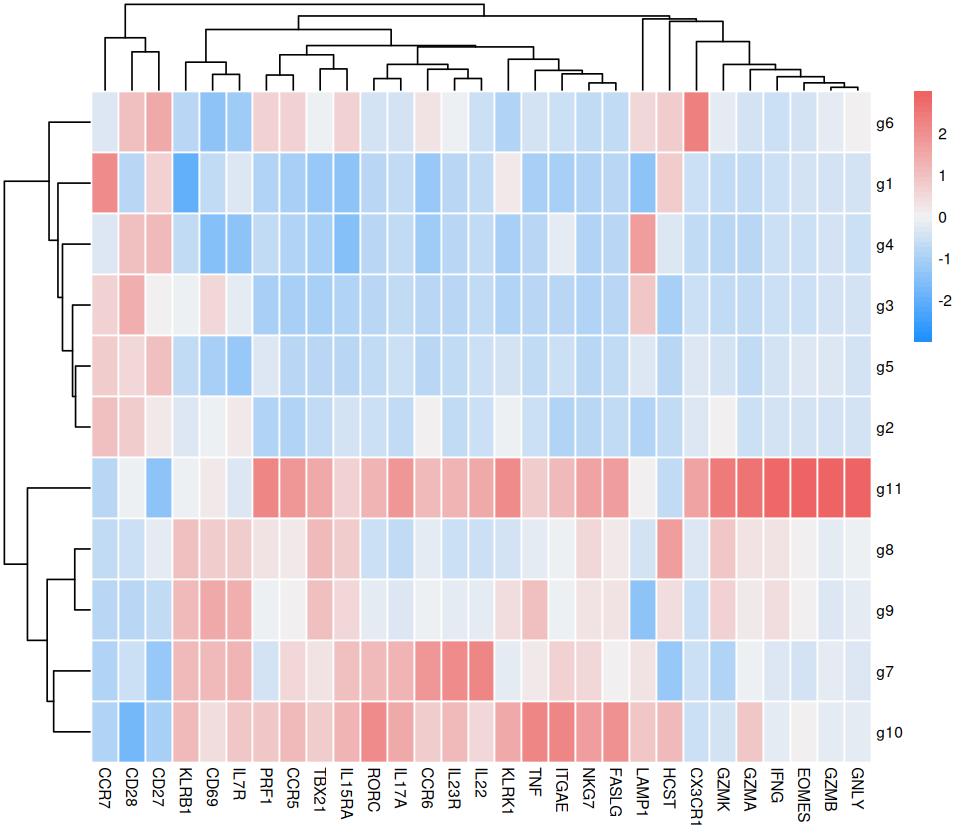

In [14]:
mat1 <- t(avgexp$RNA)

heatmap1 <- pheatmap::pheatmap(
  mat1,
  scale = "column",
  cluster_cols = TRUE,
  cluster_rows = TRUE,
  color = colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50),
  border_color = "white",
  fontsize = 9,
  width = 12, height = 4
)

# Extract gene order from heatmap1
gene_order <- colnames(mat1)[heatmap1$tree_col$order]

In [22]:
pheatmap::pheatmap(
  mat1,
  scale = "column",
  cluster_cols = TRUE,
  cluster_rows = TRUE,
  color = colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50),
  border_color = "white",
  fontsize = 9,
  width = 12, height = 4,filename = "figures/characterization_CD4CTL/heatmap_published_markers_5p.pdf"
)


## Markers CD4 CTL GSEA

In [ ]:
mrk2  <- FindAllMarkers(gut_cdn)

In [518]:
head(mrk2  %>% dplyr::filter(cluster == 11 & avg_log2FC > 1.5), n = 50)  %>% pull(gene)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene,score
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<dbl>
GZMA.6,0,2.810575,0.604,0.090,0,11,GZMA,13463.779
LINC01871.6,0,1.641294,0.616,0.183,0,11,LINC01871,3943.604
BHLHE40.6,0,1.609409,0.618,0.191,0,11,BHLHE40,3717.055
CXCR6.7,0,1.644951,0.592,0.171,0,11,CXCR6,4064.956
CTSH.6,0,2.634223,0.455,0.065,0,11,CTSH,13162.183
HLA-DPA1.5,0,1.673594,0.542,0.153,0,11,HLA-DPA1,4231.901
FABP5.6,0,1.861061,0.478,0.115,0,11,FABP5,5521.640
IFNG.7,0,3.261927,0.397,0.035,0,11,IFNG,26410.347
HLA-DRB1.5,0,1.809383,0.445,0.114,0,11,HLA-DRB1,5041.539


In [424]:
library(clusterProfiler)
library(org.Hs.eg.db)

Loading required package: AnnotationDbi


Attaching package: ‘AnnotationDbi’


The following object is masked from ‘package:clusterProfiler’:

    select


The following object is masked from ‘package:dplyr’:

    select






In [497]:
mrk_genes  <-  c('GZMB','GZMH','KLRD1','GNLY','IL17F','LINC02446','MSC','IFNG','CSF2','GZMA','CHN1','KLRK1','ZEB2','ASPM',
'FASLG','IL22','CCL4','CCL4L2','CCL3','HLA-DRB5','NKG7','CD8A','XCL2','GPR25','IL17A','CD160','NCR3','EGR2',
'LINC01871','AL359834.1','CD70','TRBV7-4','CEBPD','XCL1','HLA-DRB1','HLA-DPB1','MIR155HG','SLC4A10','PRF1','IL23R','HLA-DQA1',
'ENTPD1','CRTAM','AL606807.1','CD8B','IL21','TRGV9','FABP5','BCL2L11','CCL20','CXCR6','HIST1H1B','HLA-DPA1','TRAV1-1','LINC02195',
'CCL3L1')

In [519]:
mrk_genes  <- head(mrk2  %>% dplyr::filter(cluster == 11 & avg_log2FC > 1.5), n = 50)  %>% pull(gene)

In [528]:
ego4 <- enrichGO(gene         = mrk_genes,
                OrgDb         = org.Hs.eg.db,
                keyType       = 'SYMBOL',
                ont           = "ALL",
                pAdjustMethod = "BH",
                pvalueCutoff  = 0.01,
                qvalueCutoff  = 0.05)

In [531]:
edox <- setReadable(ego4, 'org.Hs.eg.db', 'SYMBOL')

In [534]:
log_fcs  <- mrk2  %>% dplyr::filter(cluster == 11)  %>% arrange(desc(avg_log2FC))  %>% pull(avg_log2FC) 

In [536]:
names(log_fcs)  <- mrk2  %>% dplyr::filter(cluster == 11)  %>% arrange(desc(avg_log2FC))  %>% pull(gene) 

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


png 
  2

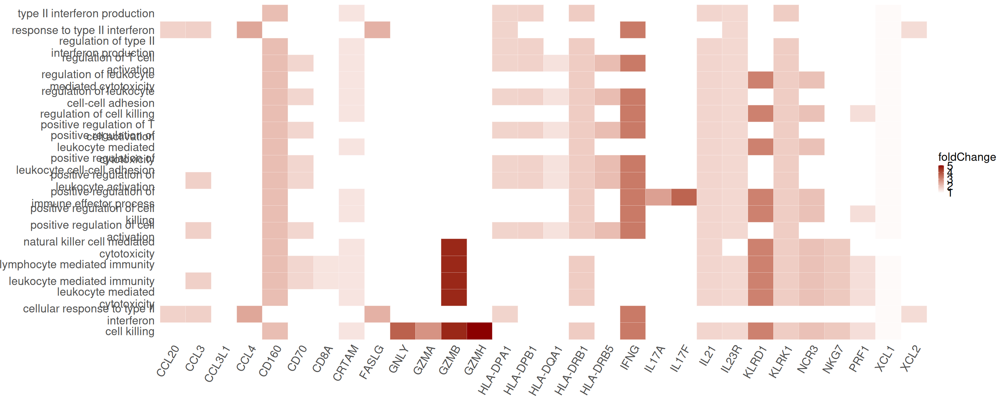

In [545]:
heatplot(edox, foldChange=log_fcs, showCategory=20) +ggtheme() +
scale_fill_gradient(low = "white", high = "red4")

pdf("./figures/heatmap_gsea_killing.pdf", width = 16, height = 7)
heatplot(edox, foldChange=log_fcs, showCategory=20) +ggtheme() +
scale_fill_gradient(low = "white", high = "red4")

dev.off()

# TCR analysis

In [47]:
all_md <- read_csv("Files/TCR_analysis/250103_tcr_all_contig_all_samples.csv")

New names:
• `` -> `...1`
Rows: 226199 Columns: 127
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (73): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (43): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
num  (3): length, reads, umis
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [48]:
all_md$`...1` <- NULL
colnames(all_md)[97:126]

[1] "is_cell"         "chain"           "contig_id"       "high_confidence"
 [5] "productive"      "length"          "reads"           "umis"           
 [9] "vdj_source"      "count_TRA"       "count_TRB"       "count_Multi"    
[13] "cdr3_A1"         "cdr3_A1_nt"      "cdr3_A2"         "cdr3_A2_nt"     
[17] "cdr3_B"          "cdr3_B_nt"       "cdr3_Multi"      "cdr3_Multi_nt"  
[21] "v_gene_A1"       "j_gene_A1"       "v_gene_A2"       "j_gene_A2"      
[25] "v_gene_B"        "d_gene_B"        "j_gene_B"        "v_gene_Multi"   
[29] "d_gene_Multi"    "j_gene_Multi"

In [49]:
md  <- gut_cdn@meta.data

In [50]:
md_joint_with_tcr <- left_join(md , all_md  %>% dplyr::select(barcode, 97:126))

Joining with `by = join_by(barcode, is_cell, chain, contig_id, high_confidence,
productive, length, reads, umis, vdj_source, count_TRA, count_TRB, count_Multi,
cdr3_A1, cdr3_A1_nt, cdr3_A2, cdr3_A2_nt, cdr3_B, cdr3_B_nt, cdr3_Multi,
cdr3_Multi_nt, v_gene_A1, j_gene_A1, v_gene_A2, j_gene_A2, v_gene_B, d_gene_B,
j_gene_B, v_gene_Multi, d_gene_Multi, j_gene_Multi)`


In [51]:
md_joint_with_tcr

orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,v_gene_Multi,d_gene_Multi,j_gene_Multi,clone_nt,clone_aa,annotations,nCount_pathwayswmean,nFeature_pathwayswmean,nCount_CollecTRI,nFeature_CollecTRI
<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<fct>,<dbl>,<int>,<dbl>,<int>
SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCAGCAGCCAAGGTACAGGGGGCCGTTTGGGGGAGCAGTACTTC NA NA,CDR3b CASSQGTGGRLGEQYF CDR3a NA,Naive_1,14.217452,9,633.3940,438
SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGCAGTGCTAGGCGGACTCCCGCGGGGGGCTCCAATGAGCAGTTCTTC NA NA,CDR3b CSARRTPAGGSNEQFF CDR3a NA,Tfh,19.829242,12,716.0750,473
SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGCGCCAGCAGCCTACAAGGACTCTCCAGCTCCTACGAGCAGTACTTC TGTGCTACGGACCTGGACGGAGCCAATAGTAAGCTGACATTT NA,CDR3b CASSLQGLSSSYEQYF CDR3a CATDLDGANSKLTF,Tfh,15.746050,10,590.8567,402
SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCACCAGCCCAACGTCAGGACAGGGGGCTTTGTACAATGAGCAGTTCTTC TGTGCTCTAGTAGGCTCTAGCAACACAGGCAAACTAATCTTT NA,CDR3b CATSPTSGQGALYNEQFF CDR3a CALVGSSNTGKLIF,Tcm,16.895136,9,626.6358,420
SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCAGCAGCTTATGGGGGGTCTCTGGAAACACCATATATTTT TGTGCAGAGAATAGGGAAACCTCCTACGACAAGGTGATATTT NA,CDR3b CASSLWGVSGNTIYF CDR3a CAENRETSYDKVIF,Naive_1,13.883640,8,672.5392,457
SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGCGCCAGCAGCACCGGACAGGAAAATCAGCCCCAGCATTTT TGTGCTCTAATACCTATGGATAGCAGCTATAAATTGATCTTC NA,CDR3b CASSTGQENQPQHF CDR3a CALIPMDSSYKLIF,Naive_1,12.477640,9,549.3504,420
SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCAGCAAGGGGGACAACCAAGAGACCCAGTACTTC NA NA,CDR3b CASKGDNQETQYF CDR3a NA,Tcm,22.347203,11,790.9303,428
SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCAGCAGCCTCCGACAGGGTAGAGACACCGGGGAGCTGTTTTTT TGTGCAGCGCTCTCTGGTTCTGCAAGGCAACTGACCTTT NA,CDR3b CASSLRQGRDTGELFF CDR3a CAALSGSARQLTF,Th17_1,15.699088,9,724.2319,461
SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NA,NA,NA,TGTGCCAGCAGCGAGGGGACAGGGTTTGCTAATGAAAAACTGTTTTTT TGTGCATCTCCAACCGGGGGAGGAACTGCTCTGATCTTT NA,CDR3b CASSEGTGFANEKLFF CDR3a CASPTGGGTALIF,Tcm,21.934770,9,636.4759,439


In [52]:
rownames(md_joint_with_tcr) <- colnames(gut_cdn)

In [53]:
is.na(md_joint_with_tcr$seurat_clusters)  %>% table

.
 FALSE 
346456 

In [54]:
gut_cdn@meta.data <- md_joint_with_tcr

In [7]:
gut_cdn@meta.data <- gut_cdn@meta.data %>% mutate(
  clone_nt = paste(cdr3_B_nt,cdr3_A1_nt,cdr3_A2_nt),
  clone_aa = paste("CDR3b",cdr3_B,"CDR3a",cdr3_A1)
)

In [9]:
metadata_6 <- gut_cdn@meta.data

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b NA CDR3a NA,129380,0
CDR3b NA CDR3a CVVSDRGSTLGRLYF,92,0
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32,0
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28,0
CDR3b NA CDR3a CAVDWNYGQNFVF,24,0
CDR3b CSAPGQGSAYGYTF CDR3a NA,22,0
CDR3b NA CDR3a CAVMDSSYKLIF,21,0
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20,0
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19,0


In [10]:
clone_table  <- clone_table  %>% dplyr::filter(!grepl(clone_aa, pattern = " NA"))

In [11]:
metadata_6$test <- 0
metadata_6 <- metadata_6 %>% group_by(test, clone_aa) %>% mutate(clone_abundance = as.numeric(n()))


metadata_6 <- as.data.frame(metadata_6 %>% mutate(clone_abundance = 
                                                  as.numeric(ifelse(clone_abundance>129370,
                                                  NA_integer_,clone_abundance))) %>%
  mutate(log_clone_abundance = log(clone_abundance, base = 2)))

In [12]:
rownames(metadata_6) <- colnames(gut_cdn)

gut_cdn@meta.data <- metadata_6

Warning message:
“Removing 129380 cells missing data for vars requested”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



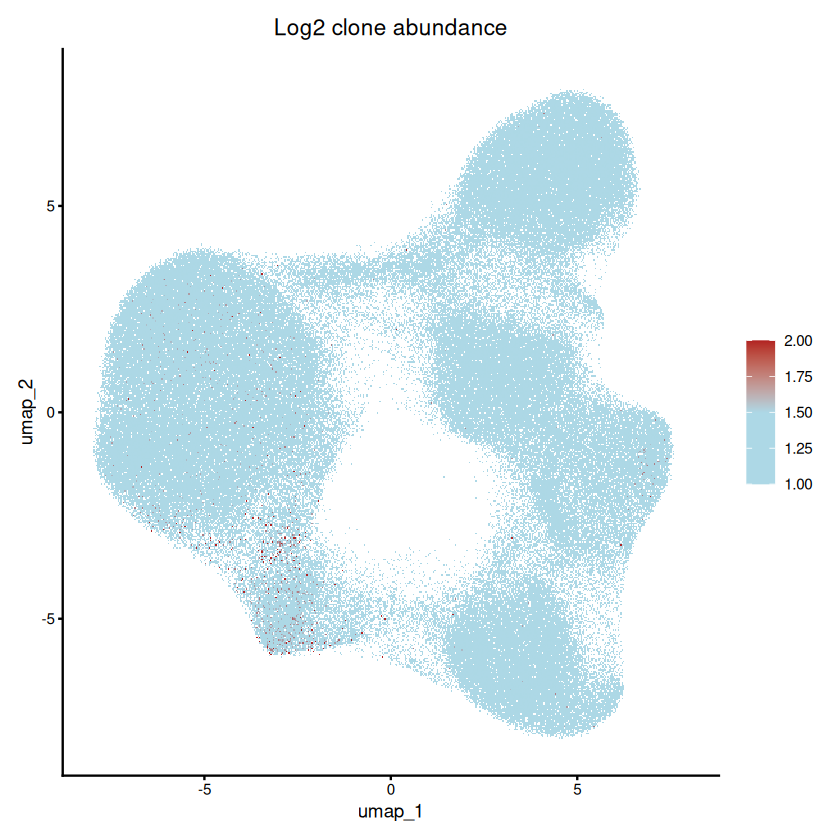

In [13]:
FeaturePlot(subset(gut_cdn, clone_abundance >=1 & clone_abundance < 2000), 
            reduction = "umap", features = "log_clone_abundance", 
            cols = c("lightblue","lightblue","firebrick"), max.cutoff = 6) + 
theme_classic() + theme(plot.title = element_text(hjust = 0.5)) + ggtitle("Log2 clone abundance")

Warning message:
“Removing 129380 cells missing data for vars requested”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



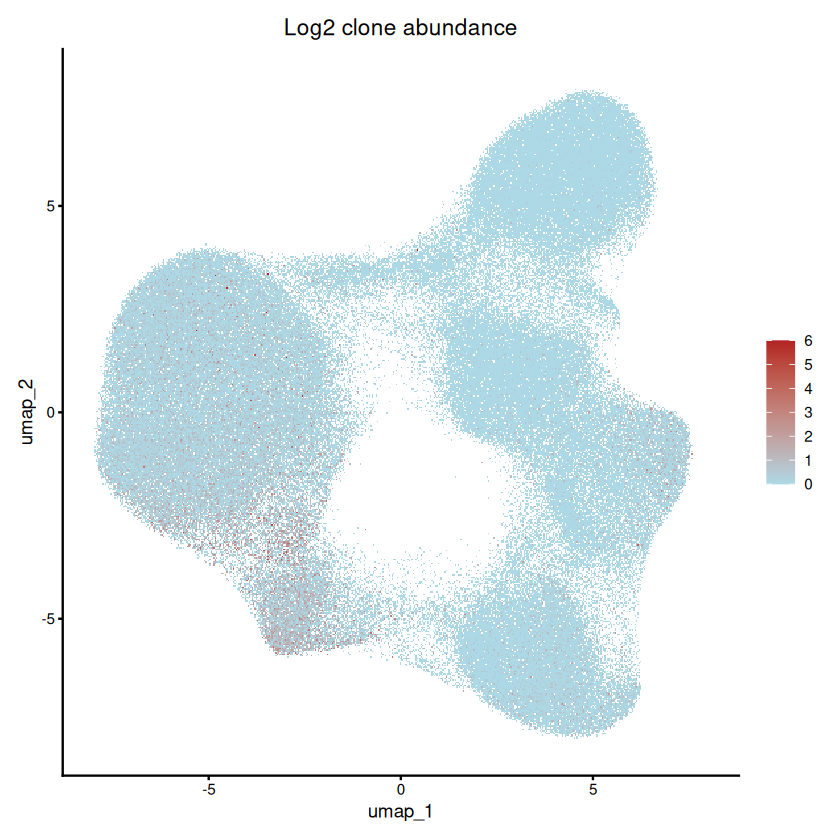

In [14]:
FeaturePlot(subset(gut_cdn, clone_abundance >=1 & clone_abundance < 2000), 
            reduction = "umap", features = "log_clone_abundance", 
            cols = c("lightblue","firebrick"), max.cutoff = 6) + 
theme_classic() + theme(plot.title = element_text(hjust = 0.5)) + ggtitle("Log2 clone abundance")

Warning message:
“Removing 129380 cells missing data for vars requested”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



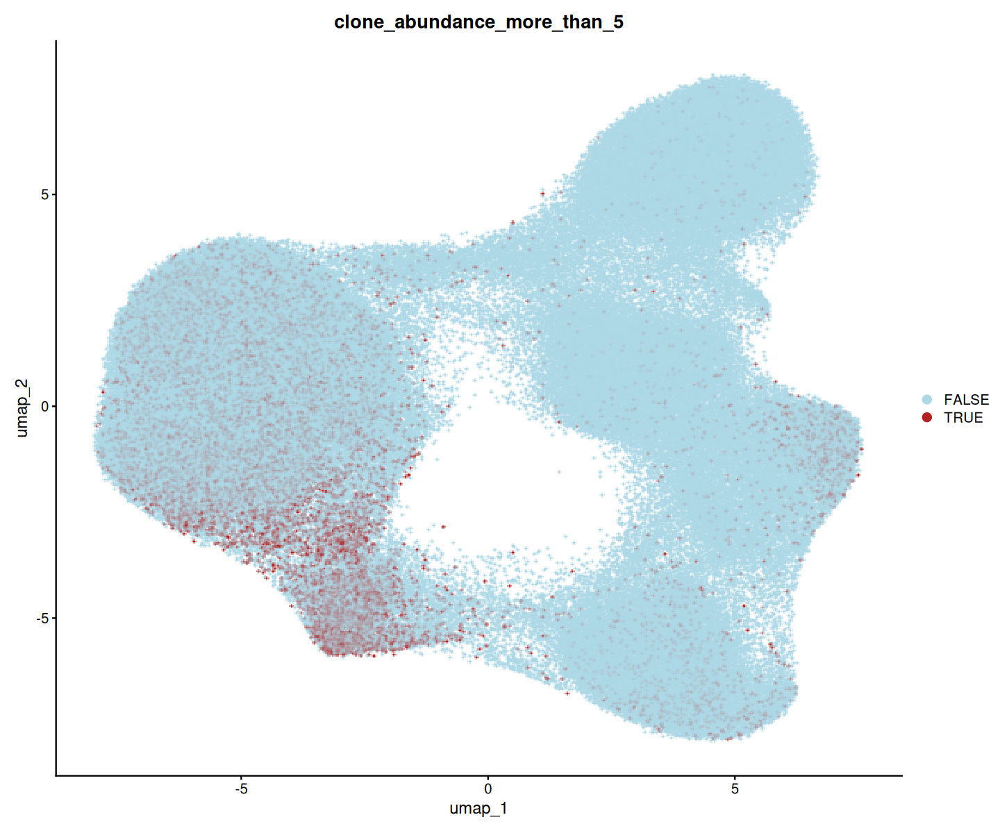

In [23]:
options(repr.plot.width = 12, repr.plot.height = 10)
gut_cdn$clone_abundance_more_than_5  <- gut_cdn$clone_abundance>2

DimPlot(subset(gut_cdn, clone_abundance >=1 & clone_abundance < 2000), 
        pt.size = 1.5, group.by = "clone_abundance_more_than_5", order = TRUE,
        cols = c("lightblue","firebrick"))

Warning message:
“Removing 129380 cells missing data for vars requested”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



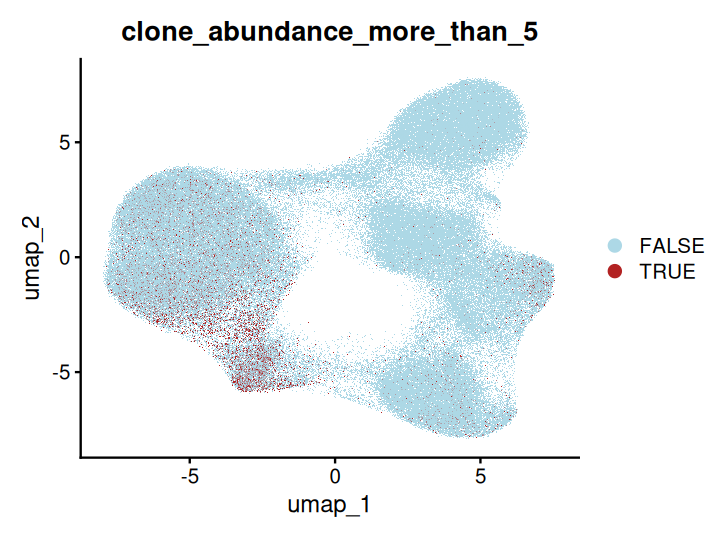

In [21]:
options(repr.plot.width = 6, repr.plot.height = 4.5)
gut_cdn$clone_abundance_more_than_5  <- gut_cdn$clone_abundance>2

DimPlot(subset(gut_cdn, clone_abundance >=1 & clone_abundance < 2000), group.by = "clone_abundance_more_than_5", order = TRUE,
        cols = c("lightblue","firebrick"))

In [41]:
# Clone abundance bar graph
metadata_6 <- metadata_6 %>%
  mutate( clone_abundance_group = case_when(clone_abundance>30 ~ ">30",
                                            clone_abundance>10 & clone_abundance<=30 ~ "11-30",
                                            clone_abundance>6 & clone_abundance<=10 ~ "6-10",
                                            clone_abundance>2 & clone_abundance<=5 ~ "3-5",
                                            clone_abundance== 2 ~ "2",
                                            clone_abundance== 1 ~ "1",
                                            TRUE ~ "1"
                                            ))

In [42]:
rownames(metadata_6) <- colnames(gut_cdn)

gut_cdn@meta.data <- metadata_6

In [15]:
metadata_6$clone_abundance  %>% table

.
     1      2      3      4      5      6      7      8      9     10     11 
188154  18228   5307   2212   1035    648    315    280    207     90     66 
    12     13     14     15     19     20     21     22     24     28     32 
    96     65     70     45     19     20     21     22     24     28     32 
    92 
    92 

In [349]:
is.na(metadata_6$annotations)  %>% table

.
 FALSE 
346456 

In [341]:
metadata_6$clone_abundance_group  %>% table

.
   >30      1  11-30      2    3-5   6-10 
   124 318182    476  18228   8554    892 

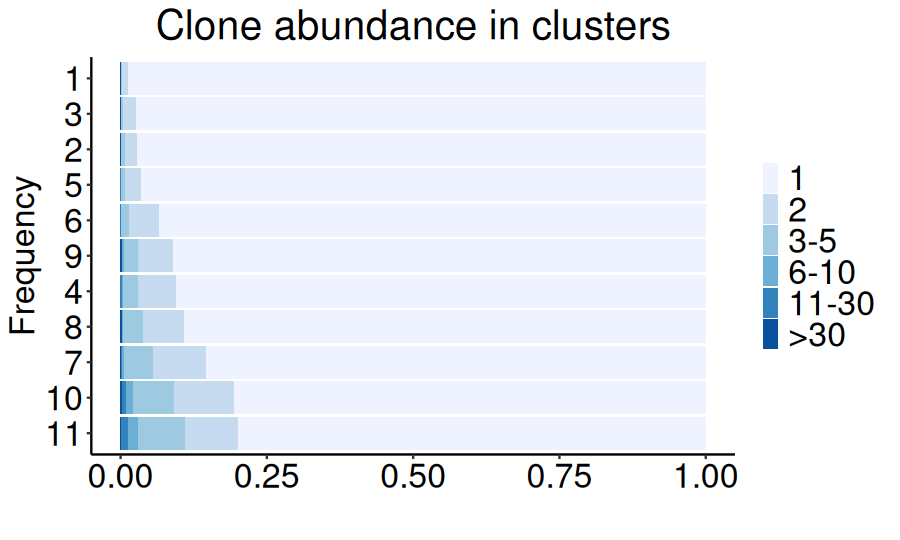

In [23]:
options(repr.plot.width = 7.5, repr.plot.height = 4.5)

metadata_6 %>% 
  filter(!is.na(clone_abundance_group)) %>% 
  ggplot(aes(x = factor(seurat_clusters, levels = c(11,10,7,8,4,9,6,5,2,3,1)))) + 
  geom_bar(aes(fill = factor(clone_abundance_group, 
                             levels = c("1","2","3-5","6-10","11-30",">30"))), position = "fill") + 
  coord_flip() +
  scale_fill_brewer(palette = "Blues") + xlab("Frequency")+
  ylab("") + 
  theme_classic() + 
  theme(plot.title = element_text(hjust = 0.5), 
        legend.position="right", 
        panel.border = element_blank(), 
        legend.title = element_blank(),
       axis.text = element_text(color = "black")) + 
  ggtitle("Clone abundance in clusters") + ggtheme() 
#ggsave("figures/tcr/clone_abundance_barplot.png", width = 30, height = 10, units = "cm")
#ggsave("figures/tcr/clone_abundance_barplot.svg", width = 30, height = 10, units = "cm")

## TCR clonality quantification

In [272]:
metadata_6  <- gut_cdn@meta.data

In [273]:
metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))  

clone_aa,n
<chr>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,15
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,14
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,14
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,14


In [274]:
more_than4_clones <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))   %>% dplyr::filter(n>4)

more_than4_clones

clone_aa,n
<chr>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,15
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,14
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,14
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,14


In [275]:
more_than2_clones <- metadata_6 %>%
  dplyr::group_by(clone_aa, participant_id, diagnosis) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))   %>% dplyr::filter(n>2)

more_than2_clones

clone_aa,participant_id,diagnosis,n
<chr>,<chr>,<chr>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,003-051,UC,32
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,003-043,FGID,28
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,001-071,CD,20
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,HE-025,HEA,19
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,003-026,CD,15
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,003-051,UC,15
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,001-074,CD,14
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,003-042,CD,14
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,003-030,UC,14


In [276]:
more_clones <- metadata_6 %>%
  dplyr::group_by(clone_aa, participant_id, diagnosis, seurat_clusters) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))    %>% 
mutate(more_than2 = if_else(n>2,1,0))

In [277]:
more_clones

clone_aa,participant_id,diagnosis,seurat_clusters,n,more_than2
<chr>,<chr>,<chr>,<fct>,<int>,<dbl>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,003-051,UC,10,25,1
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,003-043,FGID,9,20,1
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,003-051,UC,4,15,1
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,001-071,CD,10,15,1
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,003-042,CD,11,14,1
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,003-030,UC,11,14,1
CDR3b CSARGLVLYEQYF CDR3a CAVDAMLAGTASKLTF,003-072,UC,11,14,1
CDR3b CASSQETGADTQYF CDR3a CAVSGTGFQKLVF,003-046,CD,11,13,1
CDR3b CASTATSGITNEQFF CDR3a CAGVPNAGKSTF,001-026,CD,11,13,1


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



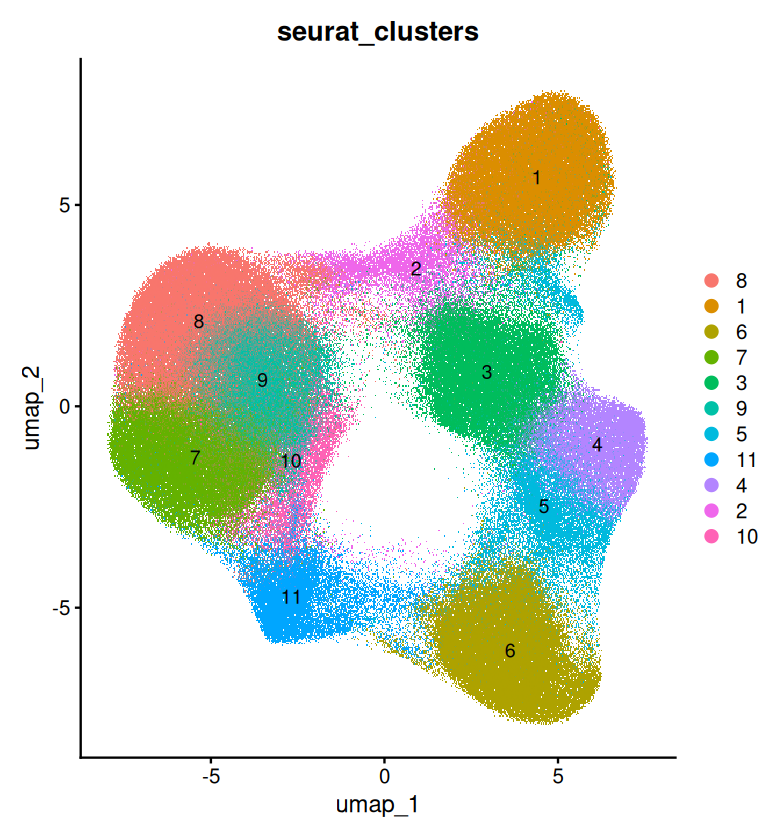

In [278]:
DimPlot(gut_cdn, group.by = "seurat_clusters", label = T)

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0), c(0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0), c(0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message:
“Computation failed in `stat_signif()`.
Caused by error in `if (p_value < .Machine$double.eps) ...`:
! missing value where TRUE/FALSE needed”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0), c(0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0), c(0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-

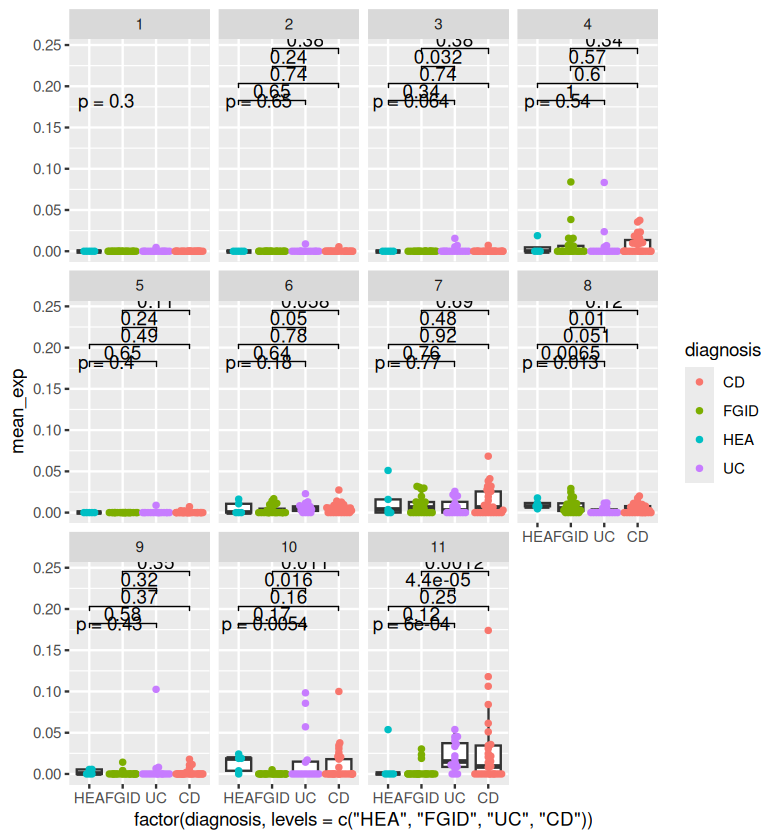

In [279]:
more_clones  %>% ungroup  %>% 

group_by(participant_id, seurat_clusters, diagnosis)  %>% 
summarise(mean_exp = mean(more_than2))  %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC"))  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD")), y = mean_exp)) +
geom_boxplot(outlier.shape = NA) +
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
facet_wrap(~factor(seurat_clusters, levels = 1:11)) +
ggpubr::stat_compare_means(label = "p.format") +
ggpubr::stat_compare_means(comparisons = list(c(1,3),c(1,4),c(2,3),c(2,4))) 


`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


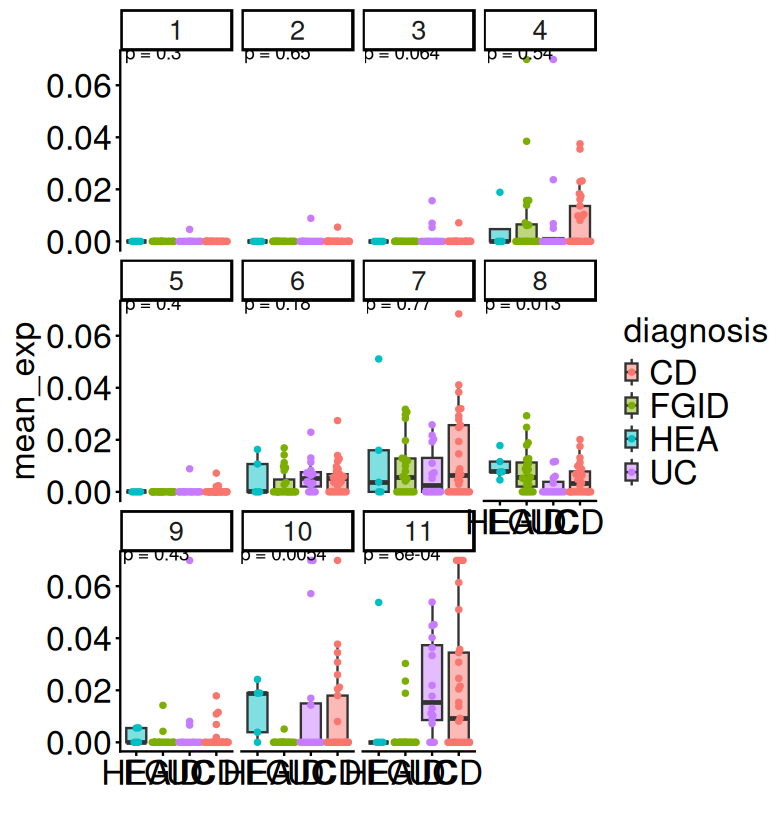

In [280]:
more_clones  %>% ungroup  %>% 

group_by(participant_id, seurat_clusters, diagnosis)  %>% 
summarise(mean_exp = mean(more_than2))  %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC"))  %>% 
mutate(mean_exp = if_else(mean_exp>0.07,0.0699,mean_exp))  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD")), y = mean_exp)) +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.5) +
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
facet_wrap(~factor(seurat_clusters, levels = 1:11)) +
ggpubr::stat_compare_means(label = "p.format") +
theme_classic() +
xlab("") +
ggtheme()
#ggsave("figures/tcr/clonal_expansion_in_diagnosis_boxplot.svg", width = 9, height = 9)

In [281]:
source_data_3b  <- more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis)  %>%
dplyr::filter(seurat_clusters == 11)  %>% 
summarise(mean_exp = mean(more_than2))  %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC"))  %>% 
mutate(mean_exp = if_else(mean_exp>0.07,0.0699,mean_exp)) 

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


In [282]:
write.csv2(source_data_3b, "tables/source_data_3b.csv")

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


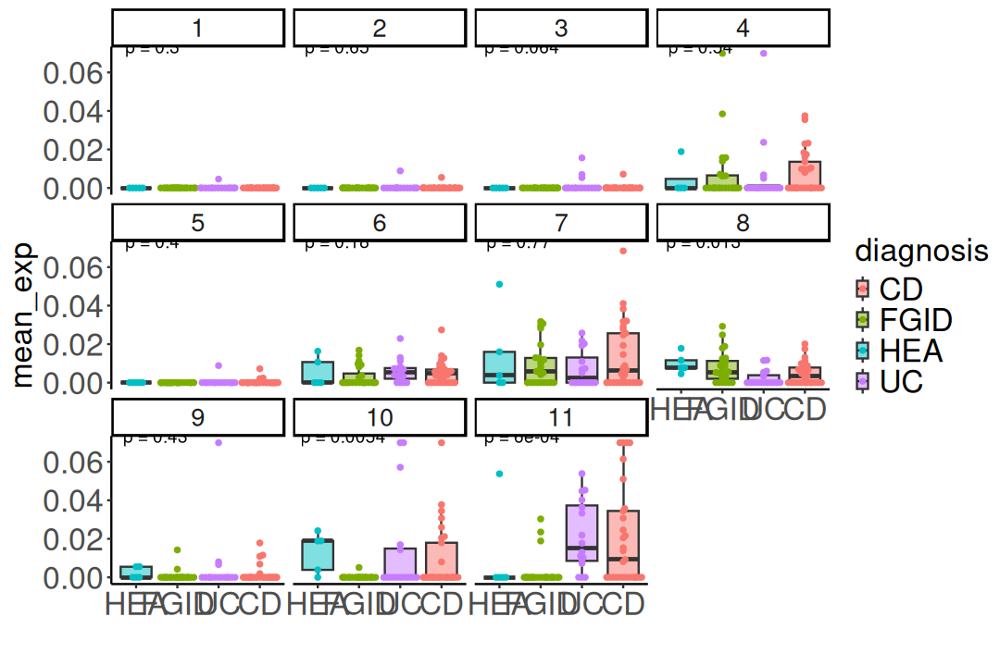

In [176]:
more_clones  %>% ungroup  %>% 

group_by(participant_id, seurat_clusters, diagnosis)  %>% 
summarise(mean_exp = mean(more_than2))  %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC"))  %>% 
mutate(mean_exp = if_else(mean_exp>0.07,0.0699,mean_exp))  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD")), y = mean_exp)) +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.5) +
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
facet_wrap(~factor(seurat_clusters, levels = 1:11)) +
ggpubr::stat_compare_means(label = "p.format") +
theme_classic() +
xlab("") +
ggtheme()
ggsave("figures/tcr/clonal_expansion_in_diagnosis_boxplot.svg", width = 9, height = 9)

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


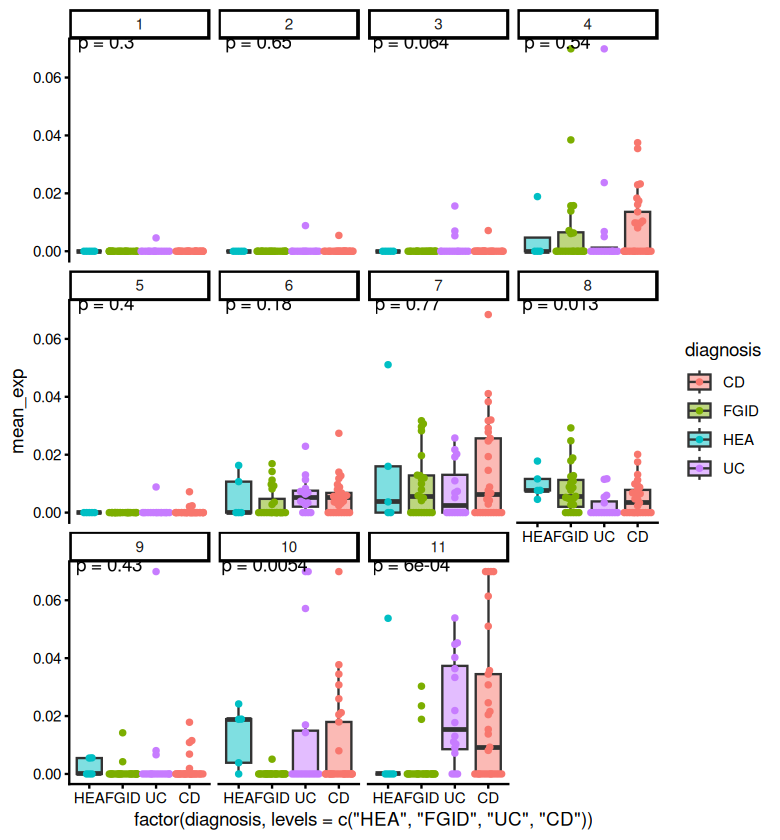

In [283]:
more_clones  %>% ungroup  %>% 

group_by(participant_id, seurat_clusters, diagnosis)  %>% 
summarise(mean_exp = mean(more_than2))  %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC"))  %>% 
mutate(mean_exp = if_else(mean_exp>0.07,0.0699,mean_exp))  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD")), y = mean_exp)) +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.5) +
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
facet_wrap(~factor(seurat_clusters, levels = 1:11)) +
ggpubr::stat_compare_means(label = "p.format") +
theme_classic()

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


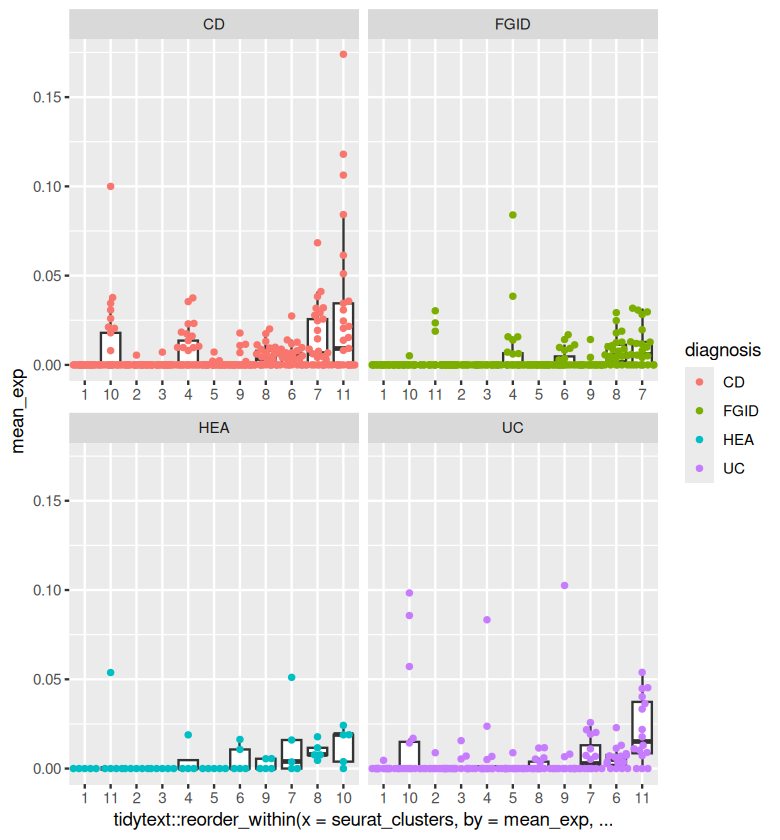

In [284]:
more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis) %>% 
summarise(mean_exp = mean(more_than2)) %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC")) %>% 
ggplot(aes(x = tidytext::reorder_within(x = seurat_clusters, by = mean_exp, within = diagnosis, fun = median), y = mean_exp)) +
geom_boxplot(outlier.shape = NA) +
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
tidytext::scale_x_reordered() +
facet_wrap(~diagnosis, scales = "free_x") 

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.
Warning message:
“Duplicated aesthetics after name standardisation: size”
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


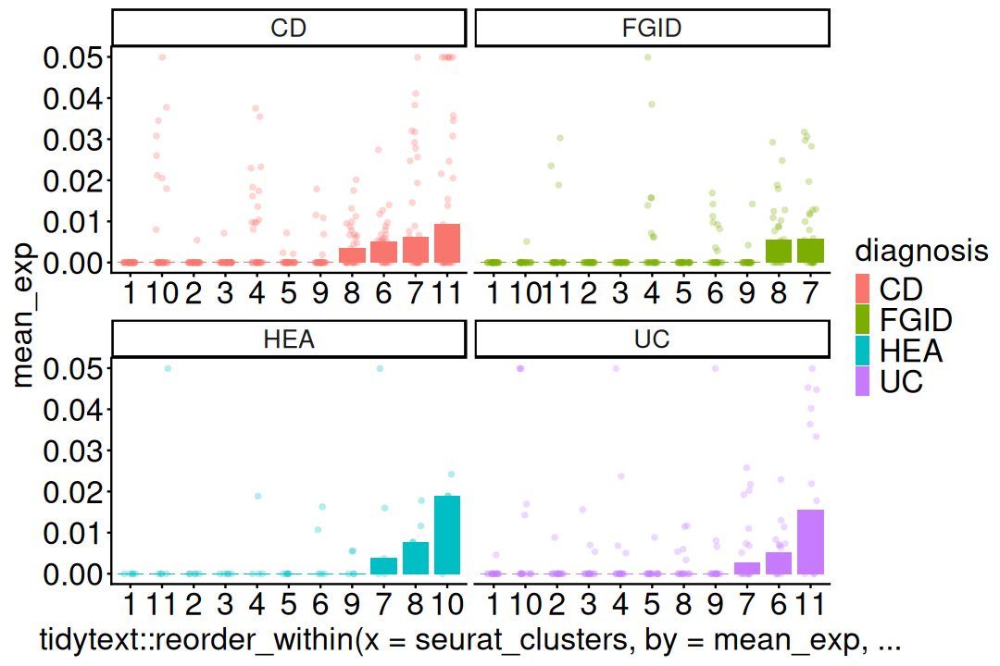

In [286]:
options(repr.plot.width = 9, repr.plot.height = 6)
more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis) %>% 
summarise(mean_exp = mean(more_than2)) %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC")) %>% 
mutate(mean_exp = if_else(mean_exp>0.05,0.0499,mean_exp))  %>% 
ggplot(aes(x = tidytext::reorder_within(x = seurat_clusters, by = mean_exp, within = diagnosis, fun = median), y = mean_exp)) +

tidytext::scale_x_reordered() +
facet_wrap(~diagnosis, scales = "free_x") +
stat_summary(fun = "median",
               geom = "bar", 
               width = 0.8,
             aes(fill = diagnosis)) +
ylim(c(0,0.05)) +
geom_jitter(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16,  alpha = 0.3, width = 0.2, height = 0) +
tidytext::scale_x_reordered() +
facet_wrap(~diagnosis, scales = "free_x")  +
theme_classic() +
ggtheme()

In [ ]:
names(pallete2) = c(1:11)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis) %>% 
summarise(mean_exp = mean(more_than2)) %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC")) %>% 
mutate(mean_exp = if_else(mean_exp>0.05,0.0499,mean_exp))  %>% 
ggplot(aes(x = tidytext::reorder_within(x = seurat_clusters, by = mean_exp, within = diagnosis, fun = median), y = mean_exp)) +

tidytext::scale_x_reordered() +
facet_wrap(~factor(diagnosis, levels = c("HEA","FGID","UC","CD")), scales = "free_x") +
stat_summary(fun = "median",
               geom = "bar", 
               width = 0.8,
             aes(fill = seurat_clusters)) +
ylim(c(0,0.05)) +
geom_jitter(size = 1.5, aes(color = seurat_clusters), cex = 2, 
                shape = 16,  alpha = 0.3, width = 0.2, height = 0) +
tidytext::scale_x_reordered() +
theme_classic() +
ggtheme() +
scale_fill_manual(values = pallete2) +
scale_color_manual(values = pallete2) +
xlab("")

ggsave("figures/tcr/clonal_expansion_in_diagnosis.svg", width = 9, height = 6)

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.
Warning message:
“Duplicated aesthetics after name standardisation: size”
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


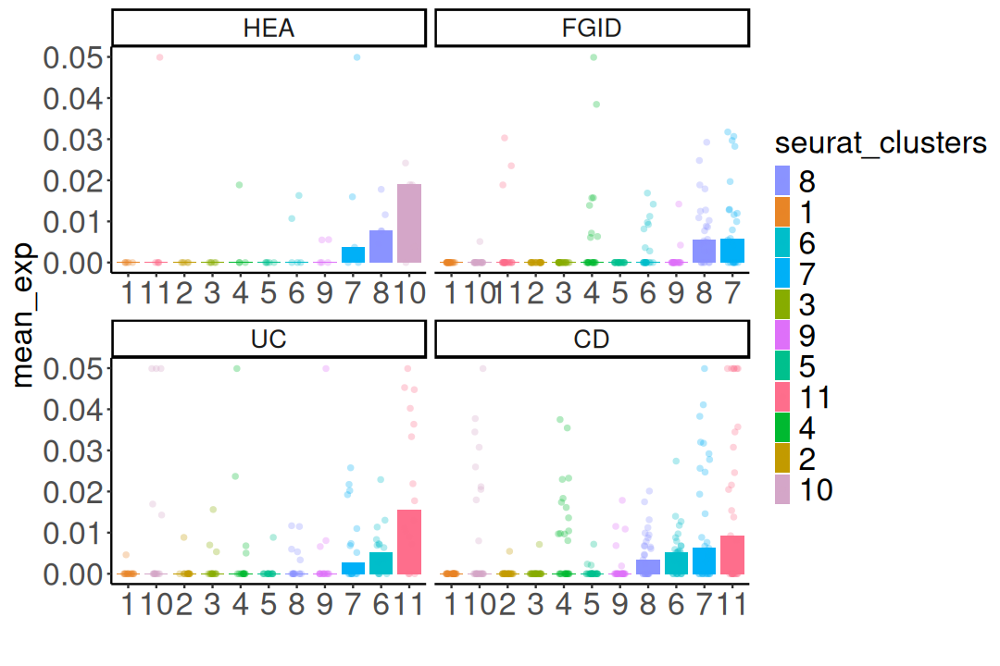

In [171]:
options(repr.plot.width = 9, repr.plot.height = 6)
more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis) %>% 
summarise(mean_exp = mean(more_than2)) %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC")) %>% 
mutate(mean_exp = if_else(mean_exp>0.05,0.0499,mean_exp))  %>% 
ggplot(aes(x = tidytext::reorder_within(x = seurat_clusters, by = mean_exp, within = diagnosis, fun = median), y = mean_exp)) +

tidytext::scale_x_reordered() +
facet_wrap(~factor(diagnosis, levels = c("HEA","FGID","UC","CD")), scales = "free_x") +
stat_summary(fun = "median",
               geom = "bar", 
               width = 0.8,
             aes(fill = seurat_clusters)) +
ylim(c(0,0.05)) +
geom_jitter(size = 1.5, aes(color = seurat_clusters), cex = 2, 
                shape = 16,  alpha = 0.3, width = 0.2, height = 0) +
tidytext::scale_x_reordered() +
theme_classic() +
ggtheme() +
scale_fill_manual(values = pallete2) +
scale_color_manual(values = pallete2) +
xlab("")

ggsave("figures/tcr/clonal_expansion_in_diagnosis.svg", width = 9, height = 6)

In [288]:
source_data_3a  <- more_clones  %>% ungroup  %>% 
group_by(participant_id, seurat_clusters, diagnosis) %>% 
summarise(mean_exp = mean(more_than2)) %>% 
dplyr::filter(diagnosis %in% c("CD","FGID","HEA","UC")) %>% 
mutate(mean_exp = if_else(mean_exp>0.05,0.0499,mean_exp))

`summarise()` has grouped output by 'participant_id', 'seurat_clusters'. You
can override using the `.groups` argument.


In [290]:
write.csv2(source_data_3a, "tables/source_data_3a.csv")

## Saving TCRb sequences for TCRMatch

In [34]:
df  <- data.frame(cdr3_b = unique(gut_cdn$cdr3_B))

In [36]:
write.csv(df, "tcrb_for_tcrmatch.csv")

## Plotting most abundant rearrangements

✔ Created directory: ../figures/tcr/cd4_5p_clones.



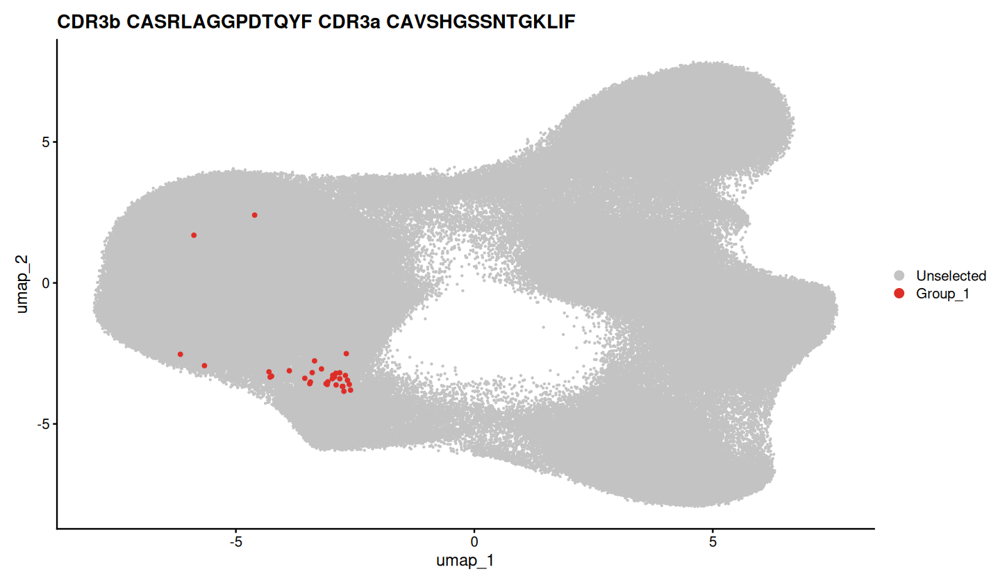

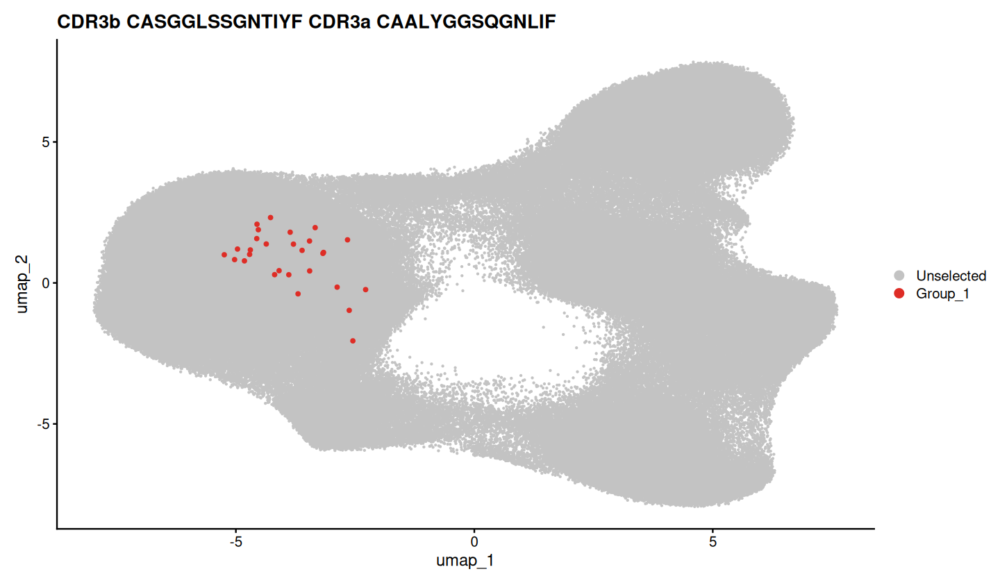

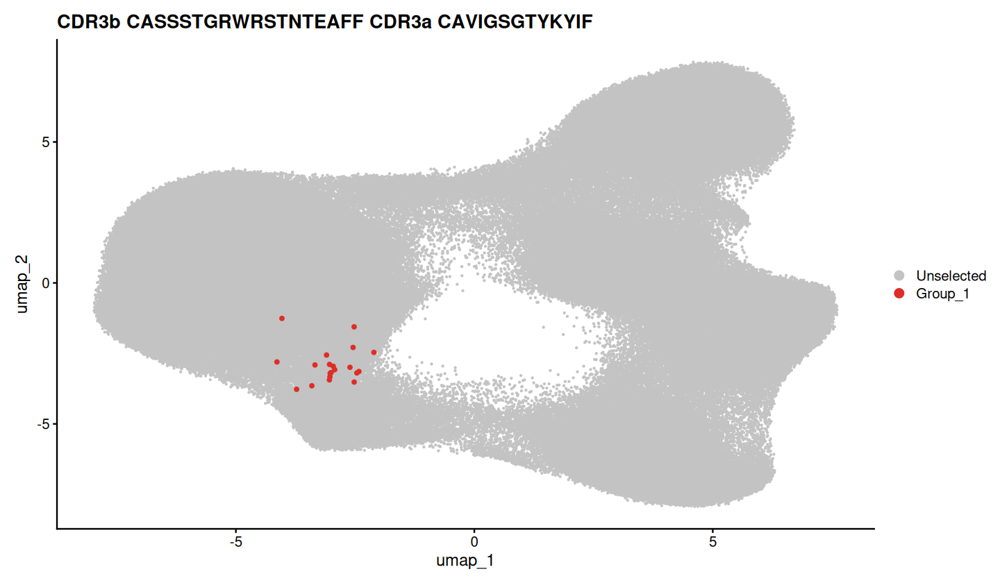

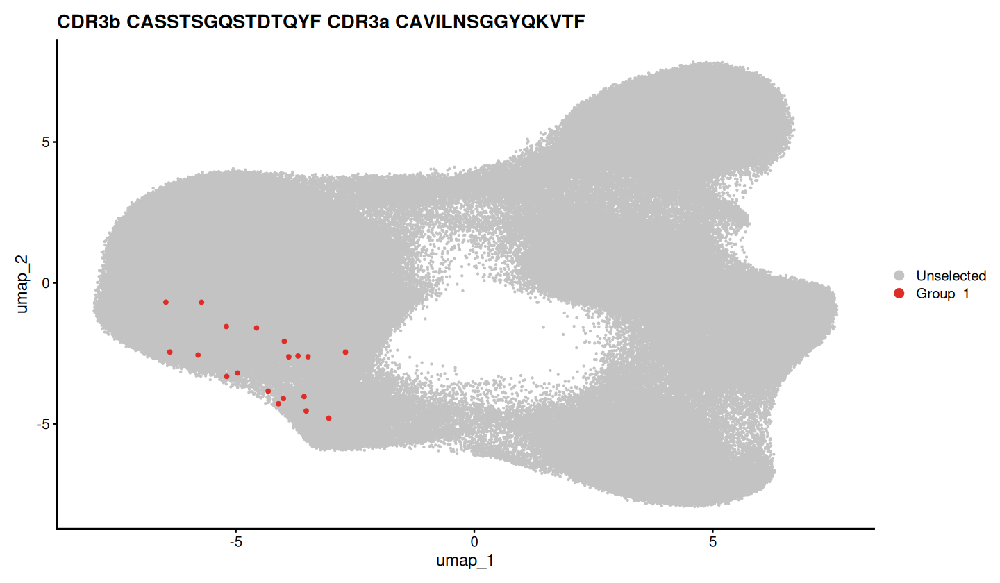

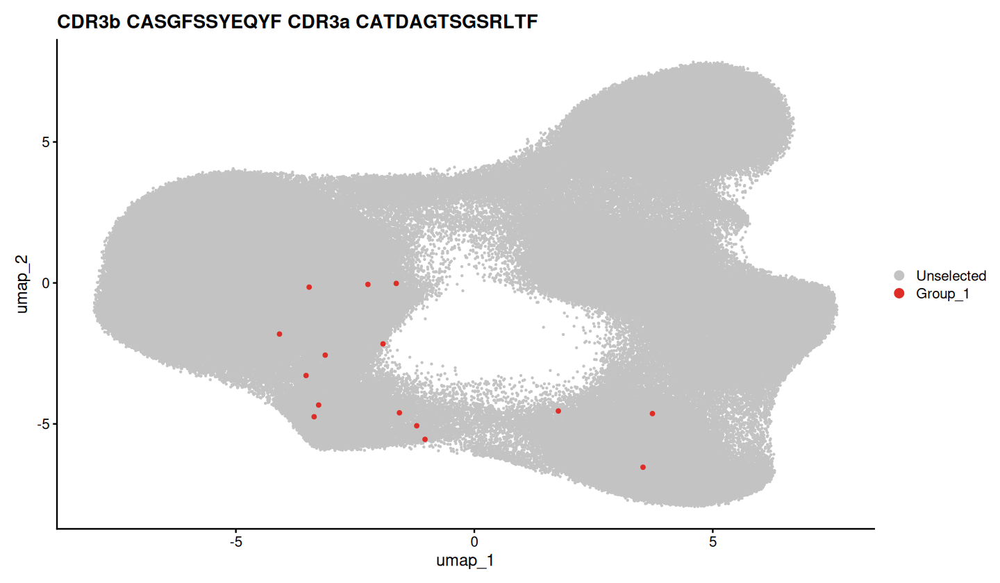

...

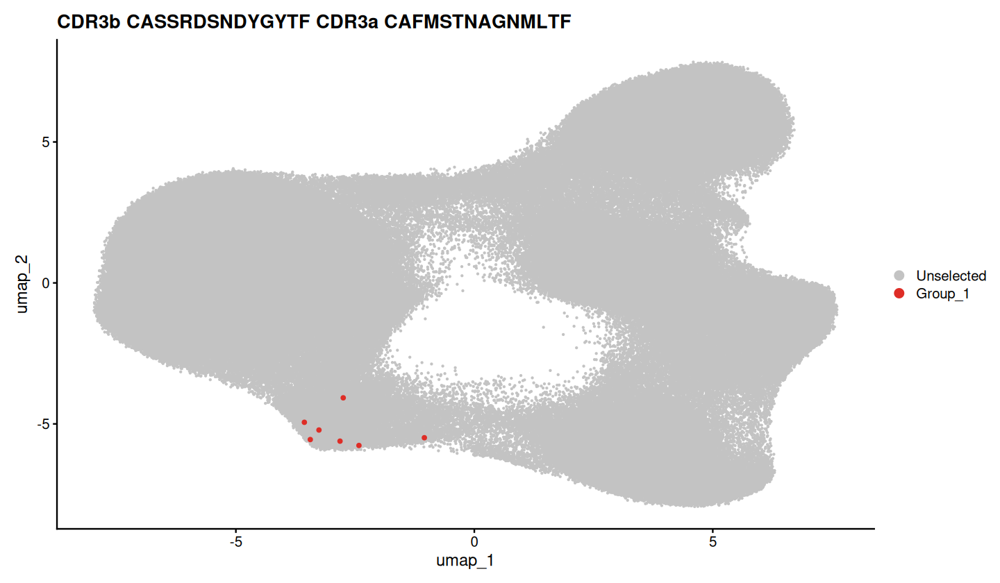

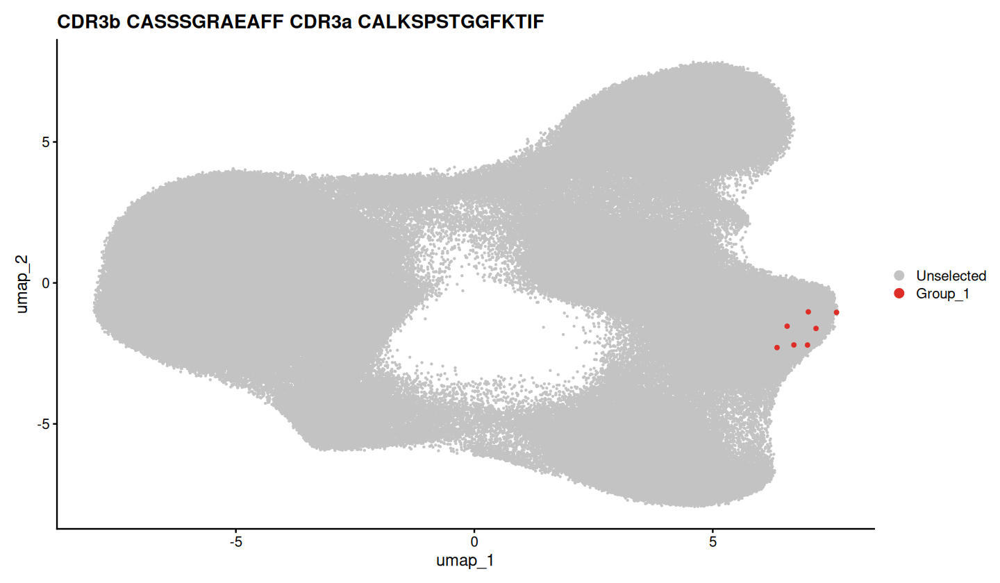

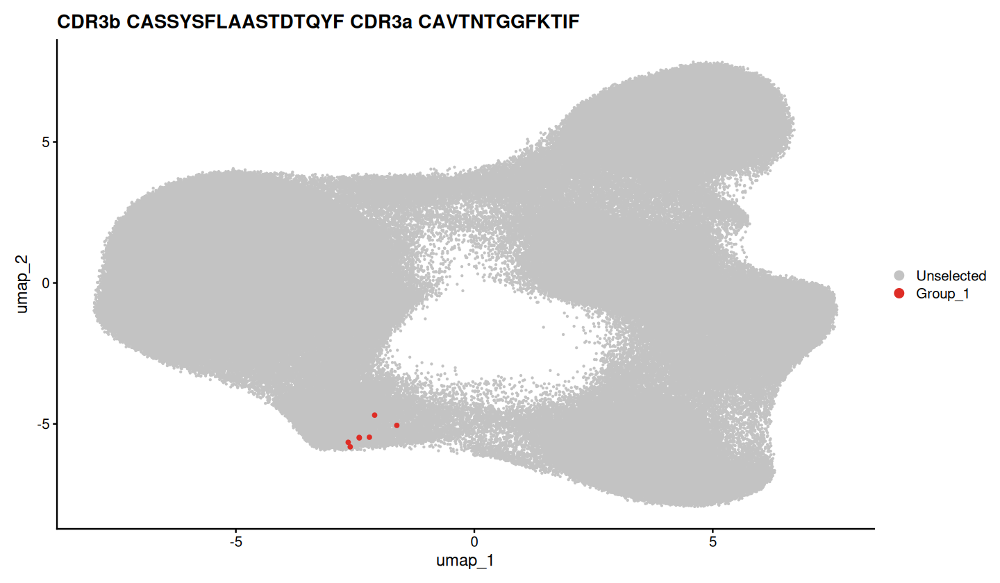

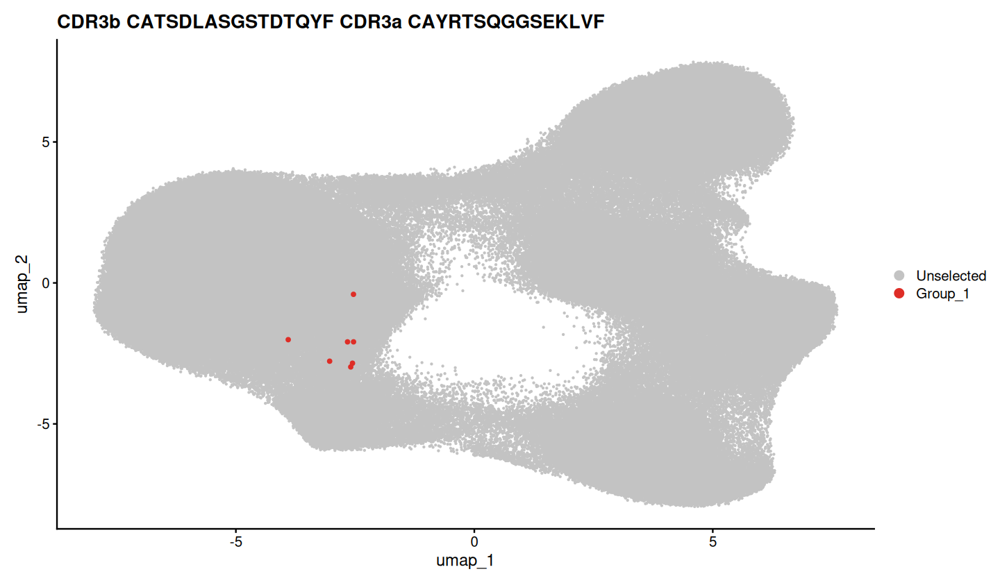

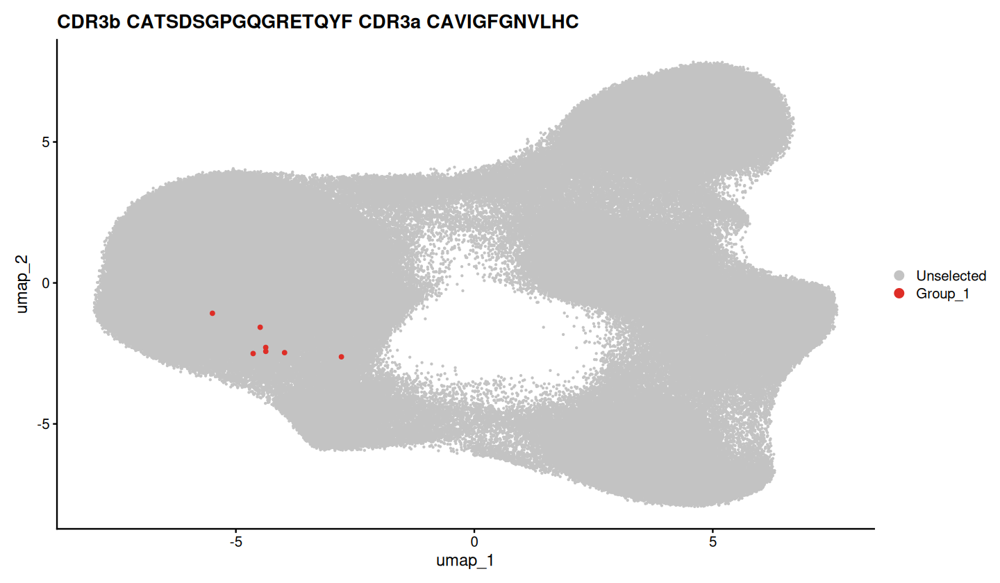

In [143]:
for(i in 1:99){
  print(DimPlot(gut_cdn, raster = F, 
          cells.highlight = colnames(gut_cdn)[grep(gut_cdn$clone_aa, 
                                                       pattern = pull(clone_table, clone_aa)[i])]) +
    ggtitle(pull(clone_table, clone_aa)[i]))
    ggsave(paste0("../figures/tcr/cd4_5p_clones/tcr_clone_",i,".png"), create.dir = TRUE, width = 13, height = 10, units = "cm")

}

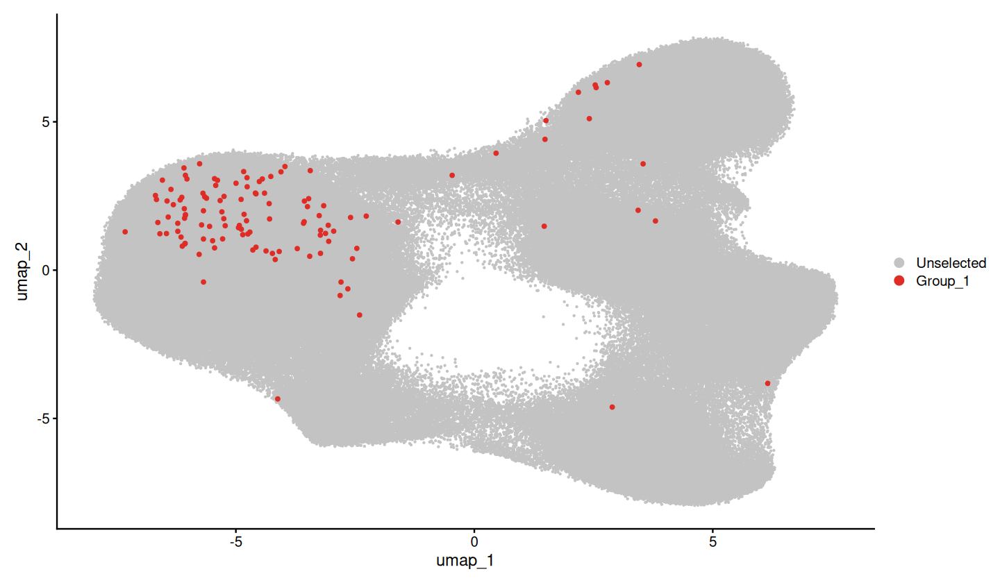

In [142]:
DimPlot(gut_cdn, cells.highlight = colnames(gut_cdn)[grep(gut_cdn$cdr3_A1, pattern = "CVVSDRGSTLGRLYF")], raster = F)

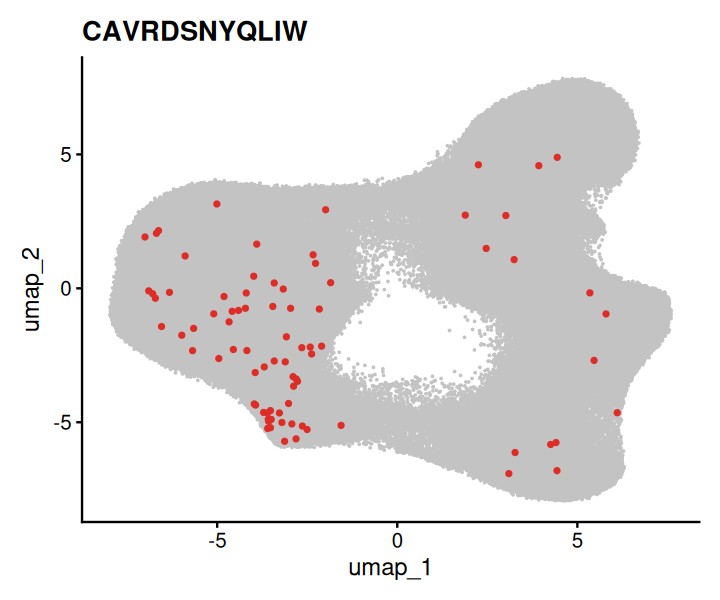

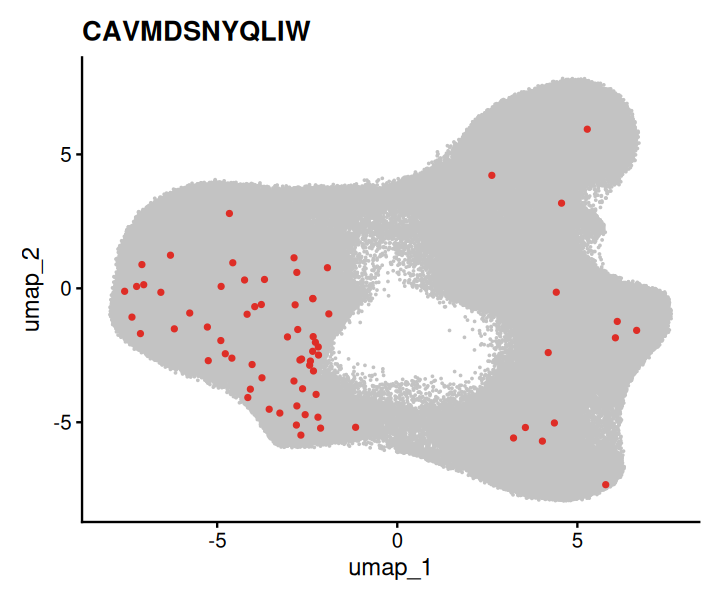

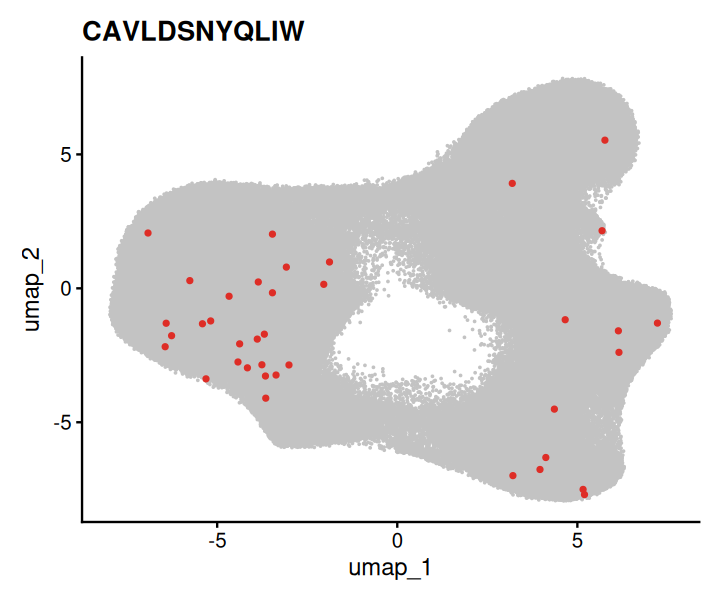

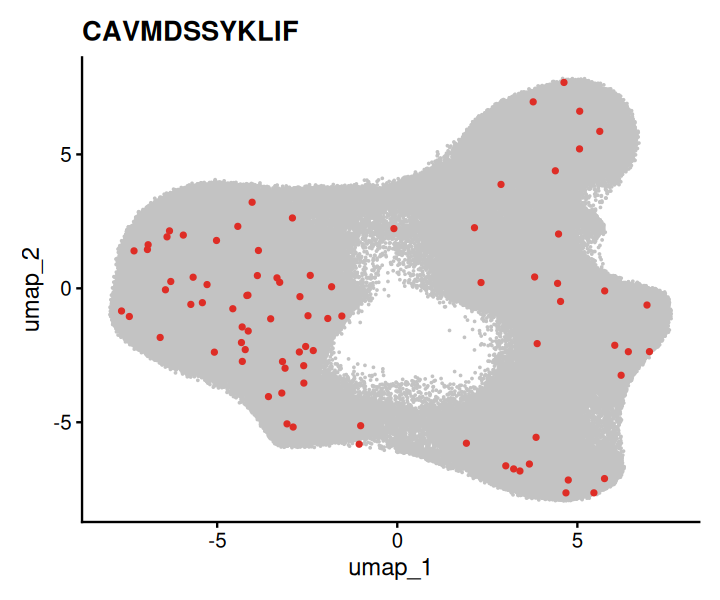

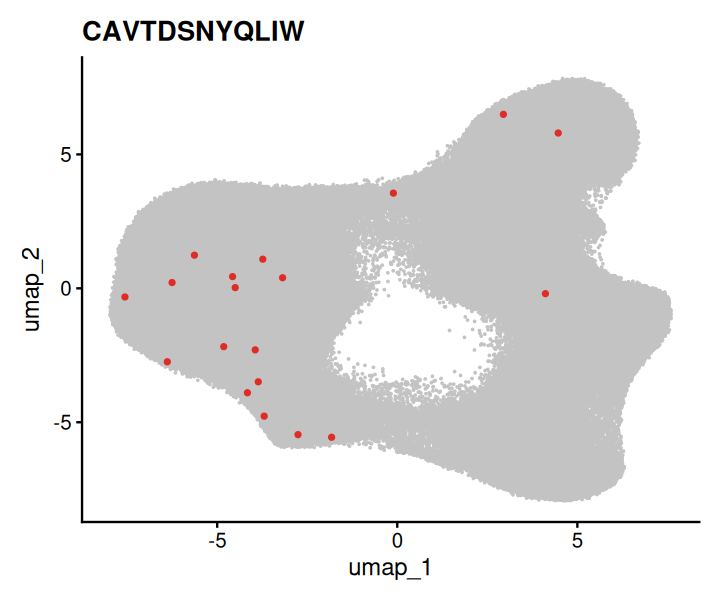

...

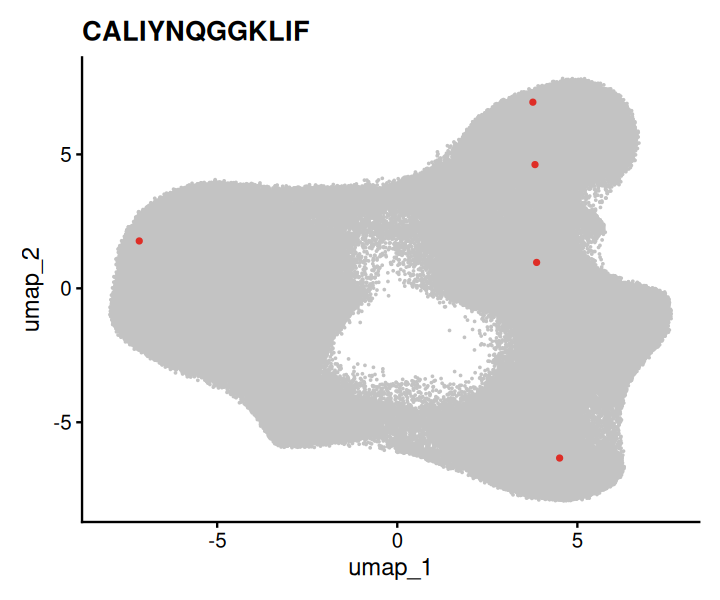

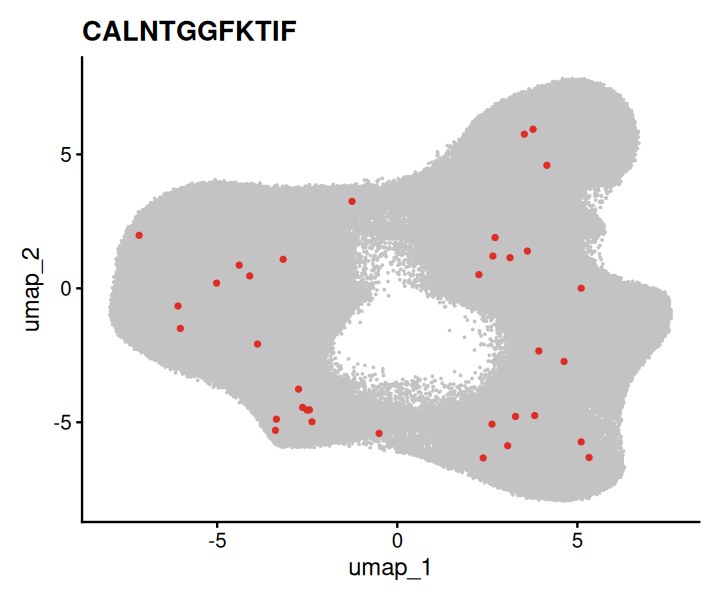

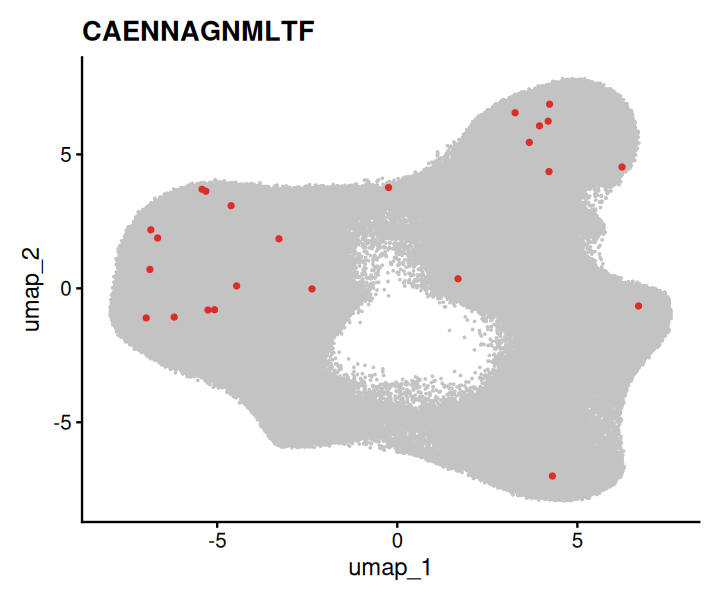

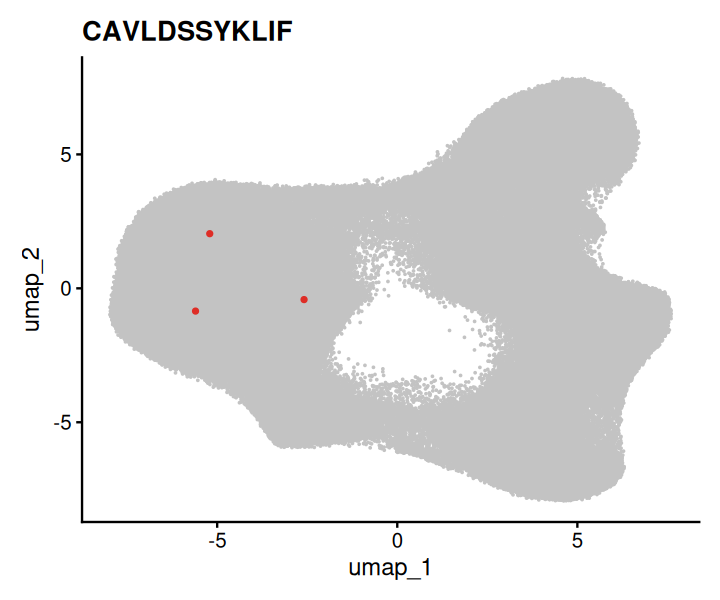

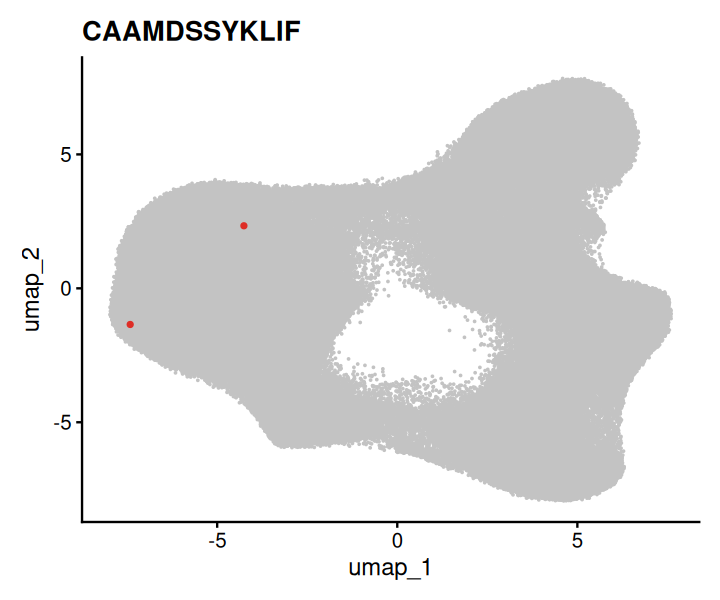

In [138]:
options(repr.plot.width = 6, repr.plot.height = 5)
for(i in c('CAVRDSNYQLIW', 'CAVMDSNYQLIW', 'CAVLDSNYQLIW', 'CAVMDSSYKLIF', 'CAVTDSNYQLIW', 'CAVRDGDYKLSF', 'CAVKDSNYQLIW', 'CAAMDSNYQLIW', 'CAALDSNYQLIW', 'CALNDYKLSF', 'CAVVDSNYQLIW', 'CVVSDRGSTLGRLYF', 'CAVIDSNYQLIW', 'CAENTGGFKTIF', 'CAVSDSNYQLIW', 'CALSGGSNYKLTF', 'CAVEDQTGANNLFF', 'CALSDSGGGADGLTF', 'CAVRDRDYKLSF', 'CAGMDSNYQLIW', 'CAVNDYKLSF', 'CAPMDSNYQLIW', 'CASMDSNYQLIW', 'CAVNRDDKIIF', 'CAENSGGSNYKLTF', 'CAPLDSNYQLIW', 'CALNSGGSNYKLTF', 'CVVNDYKLSF', 'CALSSNDYKLSF', 'CAASNQAGTALIF', 'CVVNTGNQFYF', 'CVVNTNAGKSTF', 'CAVEDTGGFKTIF', 'CAVEDSNYQLIW', 'CAVDNYGQNFVF', 'CALSDSGGSNYKLTF', 'CAVMDSSYKLIF', 'CAVNTGGFKTIF', 'CAVRDGNYQLIW', 'CALNTGFQKLVF', 'CAENTGTASKLTF', 'CAATDSNYQLIW', 'CAVNQAGTALIF', 'CAENYGGSQGNLIF', 'CAVLNRDDKIIF', 'CAVEDNYGQNFVF', 'CAVNDYKLSF', 'CVVNNARLMF', 'CAVDNYGQNFVF', 'CAVDSSASKIIF', 'CALIYNQGGKLIF', 'CALNTGGFKTIF', 'CAENNAGNMLTF', 'CAVLDSSYKLIF', 'CAAMDSSYKLIF')){
   print(DimPlot(gut_cdn, raster = F, 
                 cells.highlight = colnames(gut_cdn)[grep(gut_cdn$cdr3_A1, pattern = i)]) + NoLegend() + ggtitle(i))
   #ggsave(create.dir = TRUE, paste0("../figures/tcr/cd8_tcr/invariant_sequences2_cd8_full/",i,".png"), width = 18, height = 16, units = "cm")
} 

In [555]:
shared_clones <- c(    'CDR3b CASSQDGGYQETQYF CDR3a CALSDPGTGGFKTIF', 'CDR3b CASSEFAGTQYF CDR3a CAFRAGGTSYGKLTF',
                   'CDR3b CASSEGGFYGYTF CDR3a CAASEDNYGQNFVF', 'CDR3b CASSSGQGMNTEAFF CDR3a CAGQAGNNRKLIW', 'CDR3b CASSWGQGGYEQYF CDR3a CAVRYNTNAGKSTF', 'CDR3b CASSYSEGAGNTIYF CDR3a CAYKSGANSKLTF', 'CDR3b CATSDFSGGHQETQYF CDR3a CAYRSSQGGSEKLVF', 'CDR3b CAYRQGNTEAFF CDR3a CALSASGNTPLVF', 'CDR3b CSARGPGQGIGSPLHF CDR3a CAVGDTNAGKSTF',
                   'CDR3b CSATSGTDNSPLHF CDR3a CAMIKAAGNKLTF')

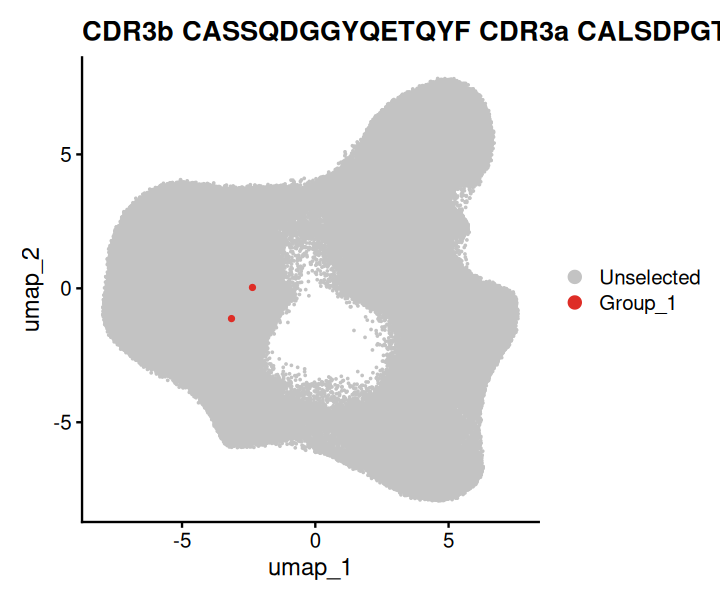

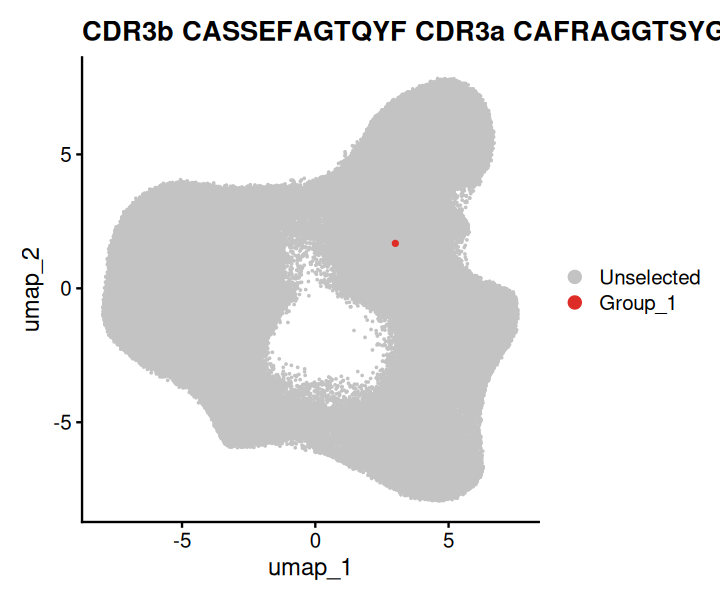

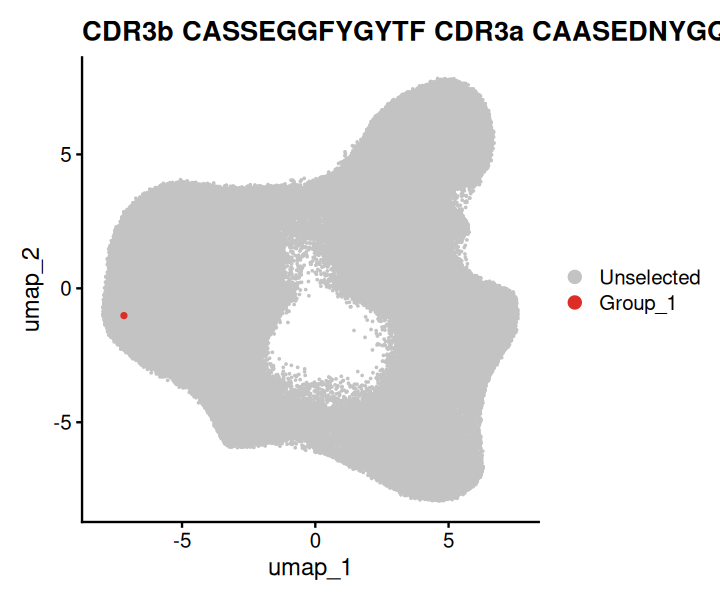

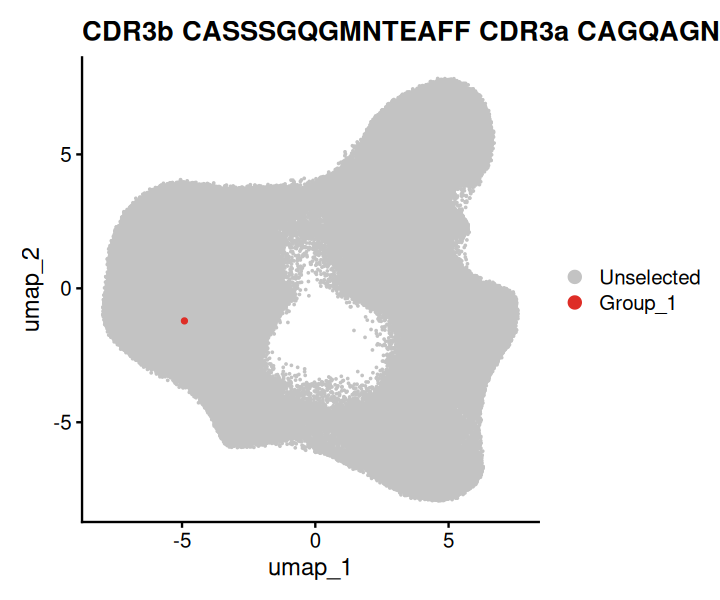

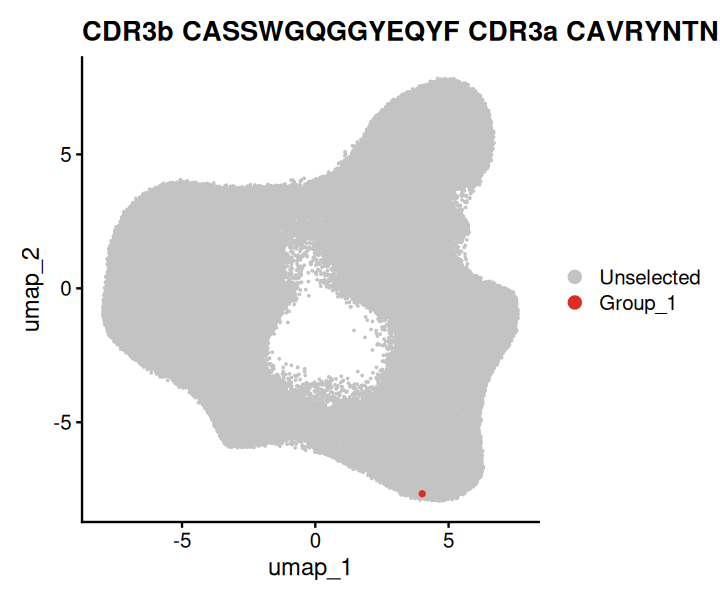

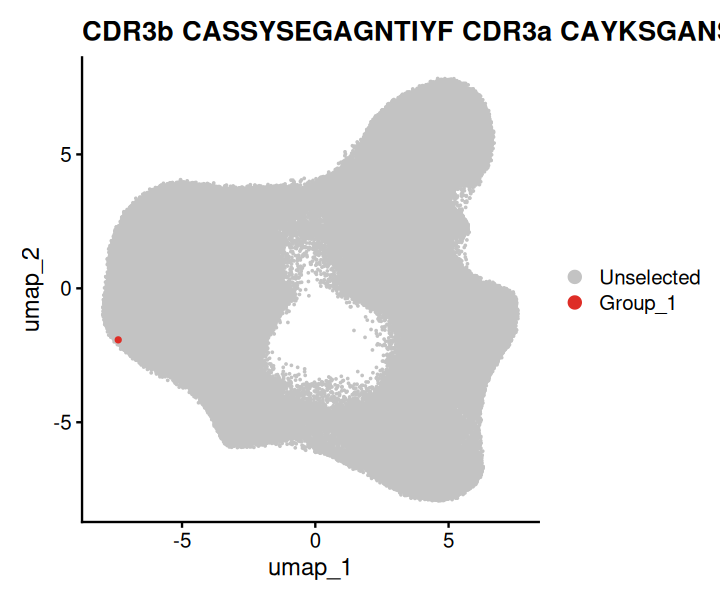

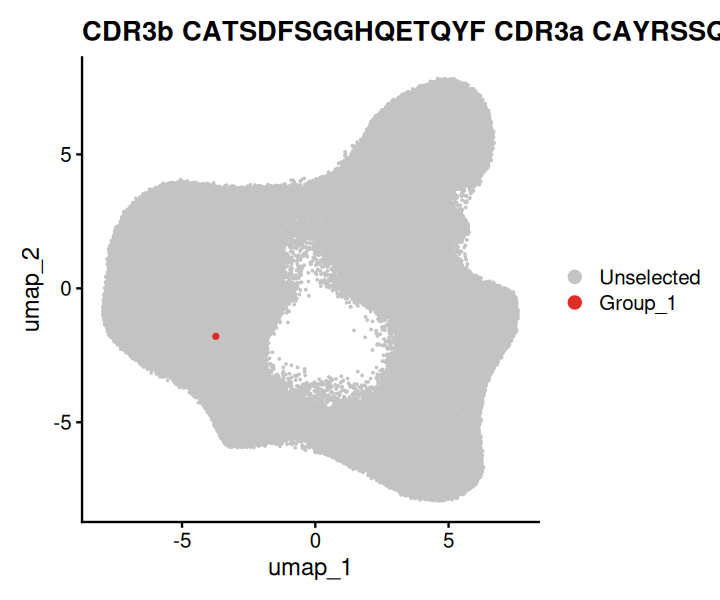

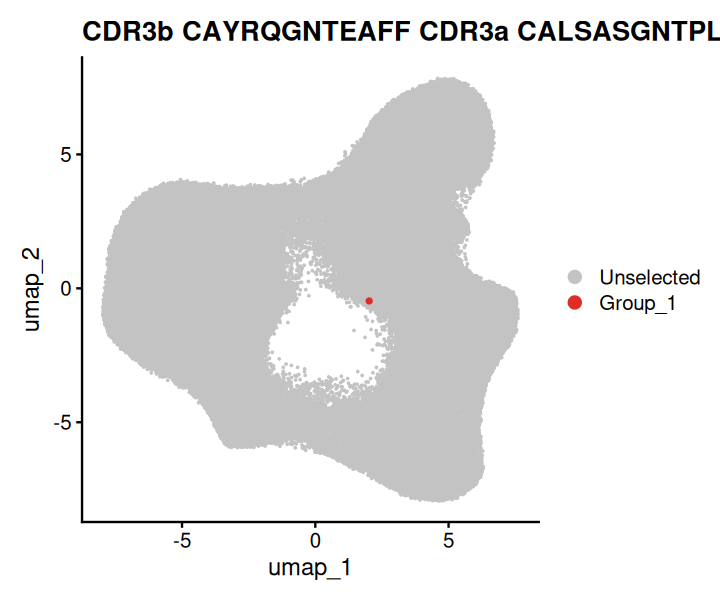

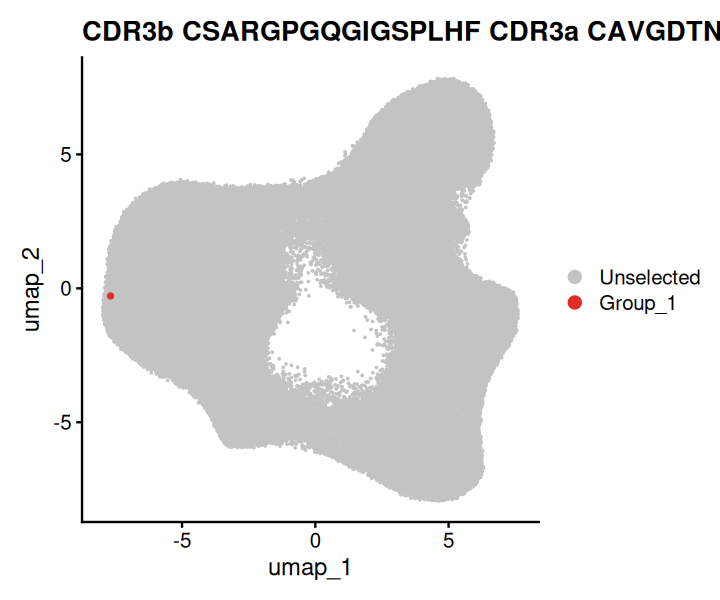

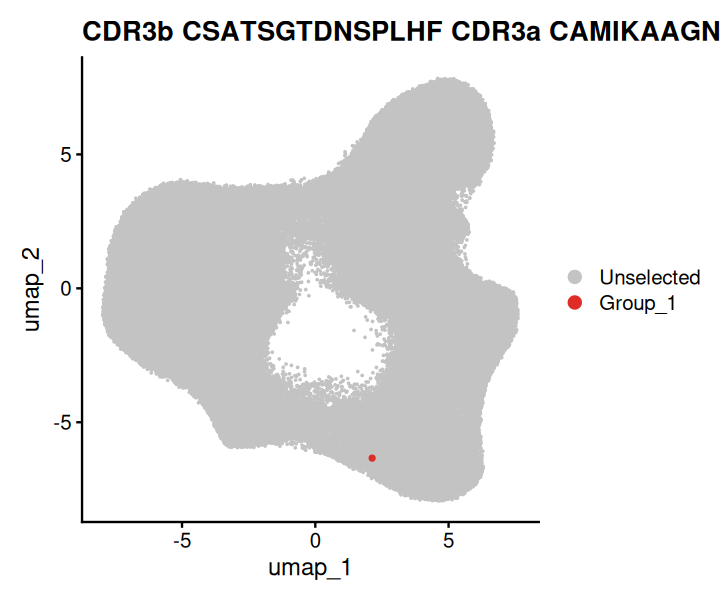

In [556]:
options(repr.plot.width = 6, repr.plot.height = 5)
for(i in shared_clones){
    print(DimPlot(gut_cdn, raster = F, 
          cells.highlight = colnames(gut_cdn)[grep(gut_cdn$clone_aa, 
                                                       pattern = i)]) +
    ggtitle(i))
}

In [ ]:
gut_cdn@meta.data  %>% dplyr::filter(clone_aa == "CDR3b CASSQDGGYQETQYF CDR3a CALSDPGTGGFKTIF")

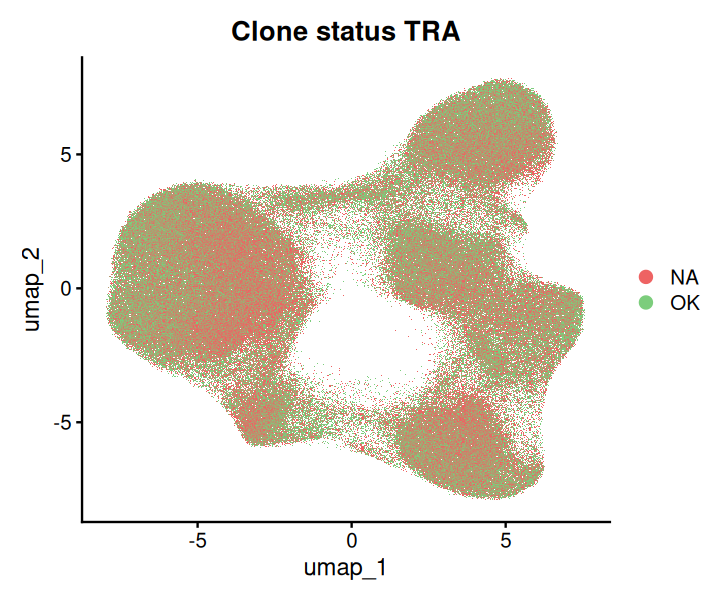

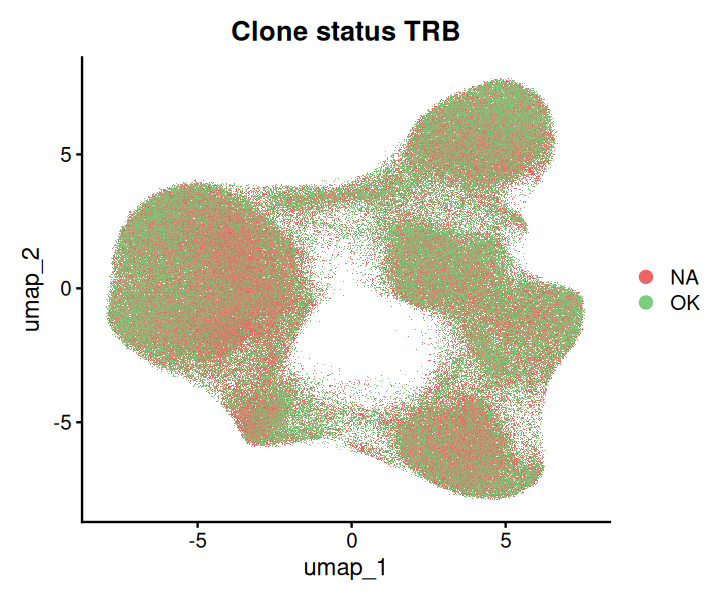

In [139]:
gut_cdn@meta.data <- gut_cdn@meta.data %>% mutate(clone_status_tra = ifelse(is.na(cdr3_A1), 
                                                      ifelse(is.na(cdr3_A2),"NA", "OK"), 
                                                      ifelse(is.na(cdr3_A2),"OK", "OK")),
                            clone_status_trb = ifelse(is.na(cdr3_B), "NA", "OK"))
                 
DimPlot(gut_cdn, group.by = "clone_status_tra", cols = c("indianred2", "palegreen3"), raster = T) + 
ggtitle("Clone status TRA")      
#ggsave(create.dir = TRUE, "../figures/tcr/cd8_tcr/seq_sufficiency/do_we_have_data_tra.png", width = 14, height = 10, units = "cm", dpi = 120)

DimPlot(gut_cdn, group.by = "clone_status_trb", cols = c("indianred2", "palegreen3"), raster = T) + 
ggtitle("Clone status TRB")      
#ggsave("../figures/tcr/cd8_tcr/seq_sufficiency/do_we_have_data_trb.png", width = 14, height = 10, units = "cm", dpi = 120)


In [ ]:
options(repr.plot.width = 24, repr.plot.height = 20)
DimPlot(gut_cdn, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(gut_cdn)[grep(gut_cdn$clone_aa, pattern = "CDR3b CASSSGQGMNTEAFF CDR3a CAGQAGNNRKLIW")], 
        sizes.highlight = 8)

In [ ]:
options(repr.plot.width = 24, repr.plot.height = 20)
DimPlot(gut_cdn, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(gut_cdn)[grep(gut_cdn$clone_aa, pattern = "CDR3b CASSSGQGMNTEAFF CDR3a CAGQTGNNRKLIW")], 
        sizes.highlight = 8)

### Overlap tissue

In [155]:
metadata_6 %>%
  dplyr::group_by(clone_aa, tissue) %>%
          tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 

    arrange(desc(n))  %>% 
pivot_wider(names_from = tissue, values_from = n, values_fill = 0)  

clone_aa,ILE,DUO,COL
<chr>,<int>,<int>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,31,1,0
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,0,22,6
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,18,0,1
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15,0,0
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,0,14,0
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,6,14,0
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,0,0,14
CDR3b CSARGLVLYEQYF CDR3a CAVDAMLAGTASKLTF,0,0,14
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,2,13,0


In [229]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


In [236]:
scale_size <- c(0,seq(10,15, by = 0.12))
names(scale_size) <- 0:35

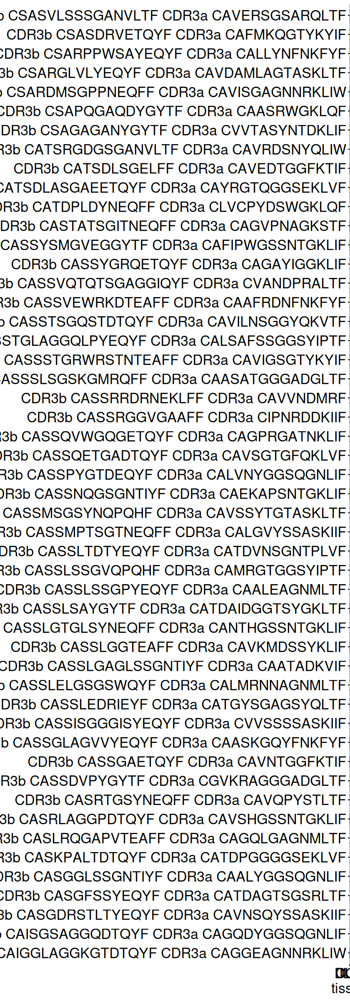

In [262]:
options(repr.plot.width = 7, repr.plot.height = 20)
metadata_6 %>%
  dplyr::group_by(clone_aa, tissue) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))  %>% 
pivot_wider(names_from = tissue, values_from = n, values_fill = 0)    %>% 
ungroup  %>% 
slice_head(n = 50)  %>% 
pivot_longer(!clone_aa, names_to = "tissue", values_to = "n")  %>% 
ggplot(aes(x = tissue, y = clone_aa)) + 
  geom_point(aes(size = as.factor(n), colour = tissue), alpha = 0.4) + 
  theme_bw() + 
scale_size_manual(values = scale_size) +
  geom_text(aes(label = n), size = 8) + 
  #scale_colour_manual(values = c("DUO" = "darkgreen", "ILE" = )) +
  theme(axis.text = element_text(color = "black")) +
ggtheme()
ggsave("figures/tcr/top50clones_by_tissue.png", create.dir = TRUE,
      width = 32, height = 58, units = "cm")
ggsave("figures/tcr/top50clones_by_tissue.svg", create.dir = TRUE,
      width = 32, height = 58, units = "cm")

In [212]:
top50_clones <- metadata_6 %>%
  dplyr::group_by(clone_aa, tissue) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))  %>% 
pivot_wider(names_from = tissue, values_from = n, values_fill = 0)    %>% 
ungroup  %>% 
slice_head(n = 50)  %>% 
pull(clone_aa)

In [213]:
top50_clones  %>% length

[1] 50

### Overlap seurat clusters

In [276]:
scale_size <- c(0,seq(13,18, by = 0.12))

In [277]:
names(scale_size) <- 0:35

In [257]:
pallete3 <- pallete2
names(pallete3) <- c(8,1,6,7,3,9,5,11,4,2,10)

In [256]:
pallete2

1         9         4         8         6         2         3         0 
"#E88526" "#C29A00" "#87AC00" "#00B930" "#00C08D" "#00BECA" "#00B0F7" "#8A93FF" 
       10         5         7 
"#DE70F9" "#D4A6C8" "#FE6E8C"

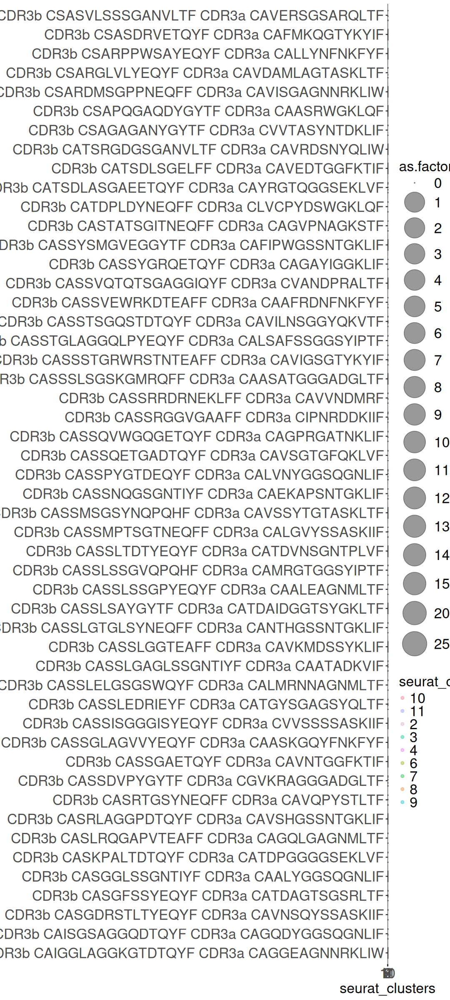

In [278]:
options(repr.plot.width = 9, repr.plot.height = 20)
metadata_6 %>% mutate(seurat_clusters2 = recode_factor(integrated_snn_res.0.6, 
                                                                              "0" = '8',
                                                                               "1" = "1",
                                                                               "2" = "6",
                                                                               "3" = "7",
                                                                               "4" = "3",
                                                                               "5" = "9",
                                                                               "6" = "5",
                                                                               "7" = "11",
                                                                               "8" = "4",
                                                                               "9" = "2",
                                                                               "10" = "10")) %>%
  dplyr::group_by(clone_aa, seurat_clusters2) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
dplyr::filter(clone_aa %in% top50_clones)  %>% 
pivot_wider(names_from = seurat_clusters2, values_from = n, values_fill = 0)    %>% 
ungroup  %>% 
slice_head(n = 50)  %>% 
pivot_longer(!clone_aa, names_to = "seurat_clusters", values_to = "n")  %>% 
ggplot(aes(x = seurat_clusters, y = clone_aa)) + 
  geom_point(aes(size = as.factor(n), colour = seurat_clusters), alpha = 0.4) + 
  theme_bw() + 
scale_size_manual(values = scale_size) +
   geom_text(aes(label = n), size = 8) + 
  theme(axis.text = element_text(color = "black")) +
  scale_colour_manual(values = pallete3) +
  theme_bw() + ggtheme()

ggsave("figures/tcr/top50clones_by_cluster.png", create.dir = TRUE,
      width = 40, height = 58, units = "cm")
ggsave("figures/tcr/top50clones_by_cluster.svg", create.dir = TRUE,
      width = 40, height = 58, units = "cm")

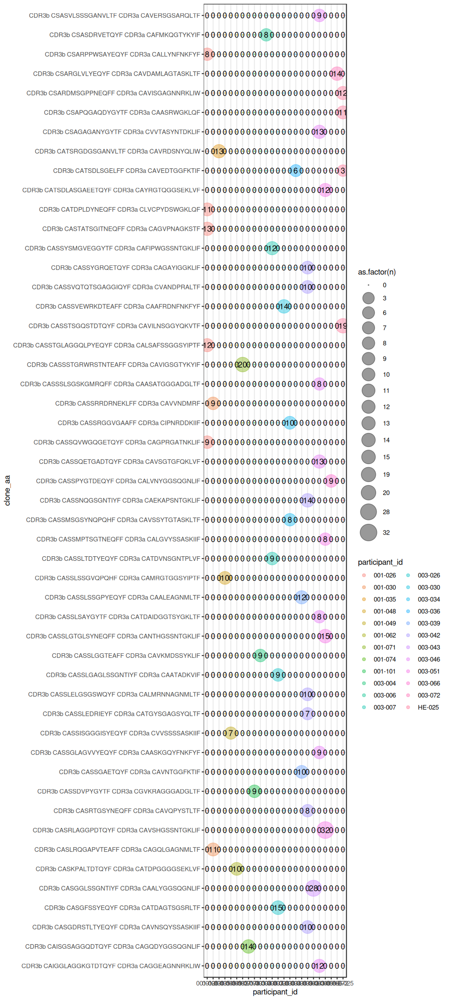

In [217]:
options(repr.plot.width = 9, repr.plot.height = 20)
metadata_6 %>%
  dplyr::group_by(clone_aa, participant_id, diagnosis) %>%
    tally %>%
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")  %>% 
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
dplyr::filter(clone_aa %in% top50_clones)  %>% 
pivot_wider(names_from = participant_id, values_from = n, values_fill = 0)    %>% 
ungroup  %>% 
slice_head(n = 50)  %>% 
pivot_longer(!clone_aa, names_to = "participant_id", values_to = "n")  %>% 
ggplot(aes(x = participant_id, y = clone_aa)) + 
  geom_point(aes(size = as.factor(n), colour = participant_id), alpha = 0.4) + 
  theme_bw() + 
scale_size_manual(values = scale_size) +
  geom_text(aes(label = n)) + 
  #scale_colour_gradient2(low = "lightskyblue", mid = "salmon", high = "indianred3", midpoint = 20) +
  theme_bw()

In [ ]:
gut_cdn

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



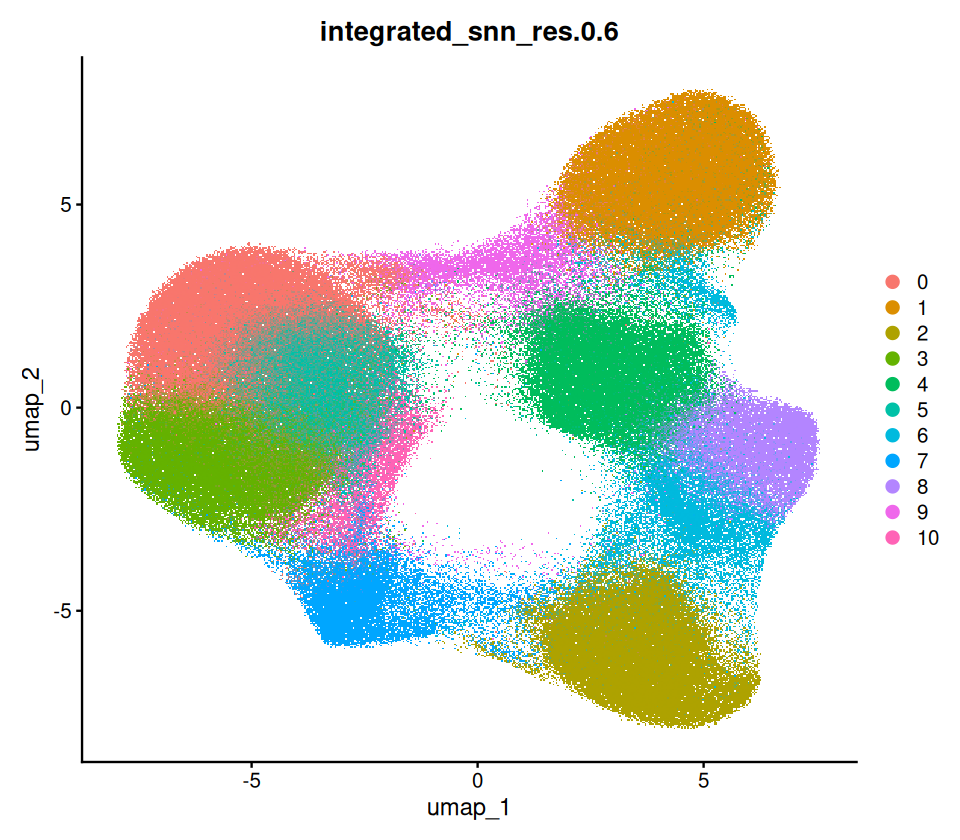

In [216]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(gut_cdn, group.by = "integrated_snn_res.0.6")

### Overlap CD4 CTL clones

In [45]:
ct2  <- metadata_6 %>%
  dplyr::group_by(clone_aa, participant_id, annotations, diagnosis) %>%
          tally  %>% 
dplyr::filter(annotations == "CTL" & !grepl(clone_aa, pattern = " NA"))

In [46]:
ct2  %>% 
arrange(desc(n))

clone_aa,participant_id,annotations,diagnosis,n
<chr>,<chr>,<fct>,<chr>,<int>
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,003-042,CTL,CD,14
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,003-030,CTL,UC,14
CDR3b CSARGLVLYEQYF CDR3a CAVDAMLAGTASKLTF,003-072,CTL,UC,14
CDR3b CASSQETGADTQYF CDR3a CAVSGTGFQKLVF,003-046,CTL,CD,13
CDR3b CASTATSGITNEQFF CDR3a CAGVPNAGKSTF,001-026,CTL,CD,13
CDR3b CSAGAGANYGYTF CDR3a CVVTASYNTDKLIF,003-046,CTL,CD,13
CDR3b CASSLSSGPYEQYF CDR3a CAALEAGNMLTF,003-039,CTL,CD,12
CDR3b CASSTGLAGGQLPYEQYF CDR3a CALSAFSSGGSYIPTF,001-026,CTL,CD,12
CDR3b CATSRGDGSGANVLTF CDR3a CAVRDSNYQLIW,001-035,CTL,FGID,12


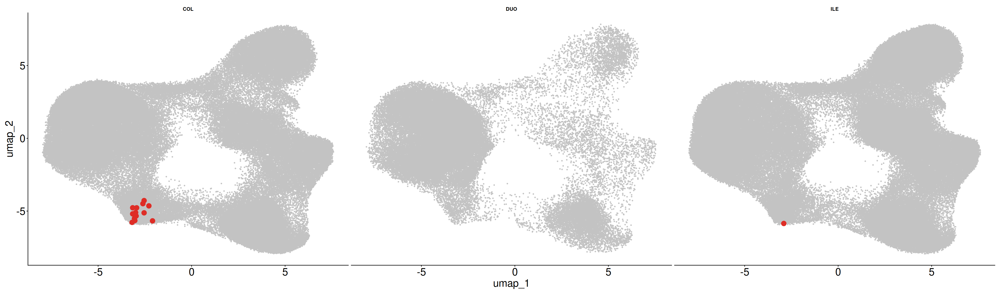

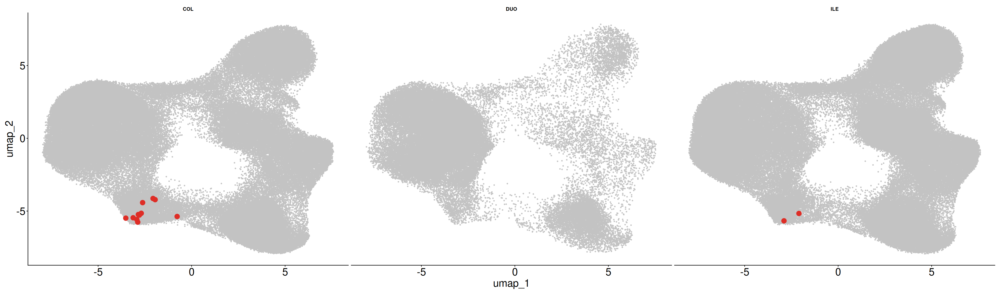

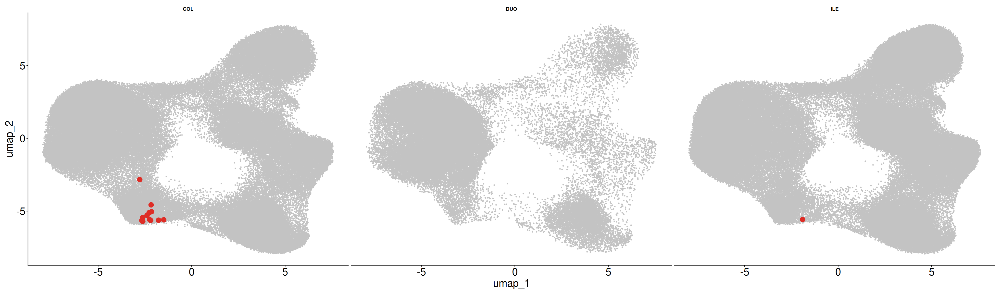

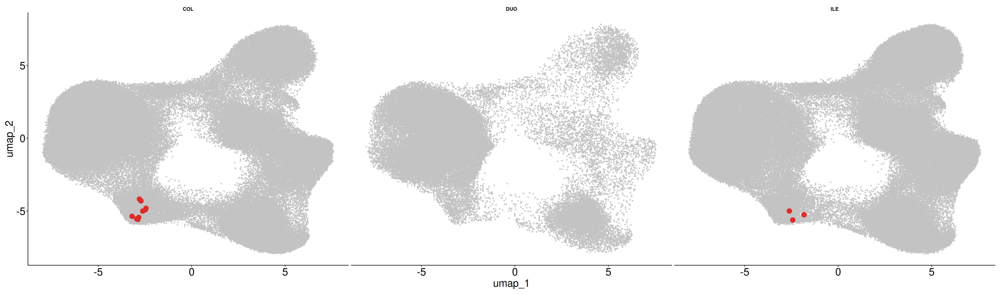

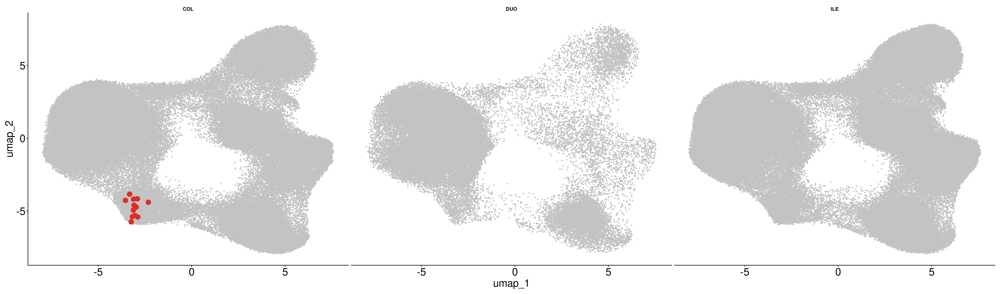

In [51]:
options(repr.plot.width = 34, repr.plot.height = 10)

for(i in c(
"CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF",
"CDR3b CASSQETGADTQYF CDR3a CAVSGTGFQKLVF",
"CDR3b CASTATSGITNEQFF CDR3a CAGVPNAGKSTF",
"CDR3b CSAGAGANYGYTF CDR3a CVVTASYNTDKLIF",
"CDR3b CASSLSSGPYEQYF CDR3a CAALEAGNMLTF"
    

)){
  print(DimPlot(gut_cdn, raster = F, pt.size = 0.5, split.by = "tissue", sizes.highlight = 5,
           cells.highlight = colnames(gut_cdn)[grep(gut_cdn$clone_aa, pattern = i)]) + 
    NoLegend() + theme(axis.text = element_text(size = 25), title = element_text(size = 25)))
   }

## TCR centroids

In [46]:
metadata_6  <- gut_cdn@meta.data

In [47]:
metadata_7  <- gut_cdn@reductions$umap@cell.embeddings %>% as.data.frame()   %>% 
rownames_to_column("barcode") %>% left_join(dplyr::select(metadata_6, clone_aa, barcode, annotations, diagnosis))

Joining with `by = join_by(barcode)`


In [48]:
metadata_7

barcode,umap_1,umap_2,clone_aa,annotations,diagnosis
<chr>,<dbl>,<dbl>,<chr>,<fct>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,4.4166991,5.49561566,CDR3b CASSQGTGGRLGEQYF CDR3a NA,Naive_1,FGID
AAACCTGCAGTCACTA-1_1193610_1_1_1,4.2522875,-1.59849209,CDR3b CSARRTPAGGSNEQFF CDR3a NA,Tfh,FGID
AAACCTGCATCGGACC-1_1193610_1_1_1,5.1139971,-0.37078244,CDR3b CASSLQGLSSSYEQYF CDR3a CATDLDGANSKLTF,Tfh,FGID
AAACCTGTCGCCAGCA-1_1193610_1_1_1,2.7365910,0.82743430,CDR3b CATSPTSGQGALYNEQFF CDR3a CALVGSSNTGKLIF,Tcm,FGID
AAACCTGTCGCGATCG-1_1193610_1_1_1,4.3603634,5.27745503,CDR3b CASSLWGVSGNTIYF CDR3a CAENRETSYDKVIF,Naive_1,FGID
AAACCTGTCTTCGGTC-1_1193610_1_1_1,6.0077654,5.97292584,CDR3b CASSTGQENQPQHF CDR3a CALIPMDSSYKLIF,Naive_1,FGID
AAACGGGAGCGTTTAC-1_1193610_1_1_1,3.1118924,0.56945919,CDR3b CASKGDNQETQYF CDR3a NA,Tcm,FGID
AAACGGGCACAGACTT-1_1193610_1_1_1,-5.3855017,-2.49158604,CDR3b CASSLRQGRDTGELFF CDR3a CAALSGSARQLTF,Th17_1,FGID
AAACGGGCAGGTGCCT-1_1193610_1_1_1,2.3069629,-0.05360401,CDR3b CASSEGTGFANEKLFF CDR3a CASPTGGGTALIF,Tcm,FGID


In [49]:
centroids  <- metadata_7  %>% group_by(clone_aa)  %>% summarise(cen_x = mean(umap_1), cen_y = mean(umap_2))

In [50]:
centroids

clone_aa,cen_x,cen_y
<chr>,<dbl>,<dbl>
CDR3b CAAAEREGEQYF CDR3a CAVGNSGYSTLTF,-5.034835,-1.8843418
CDR3b CAAAGRADTQYF CDR3a CAAGDGTSYGKLTF,-4.065276,-1.3368242
CDR3b CAAAIIIQGATEAFF CDR3a NA,6.765295,-0.8611382
CDR3b CAAAPGGVDNEQFF CDR3a CAVGPIGFGNVLHC,5.182675,7.0228292
CDR3b CAAAREEDTEAFF CDR3a CALSSASKLTF,-4.787600,3.2774278
CDR3b CAAARTSGANVLTF CDR3a CAVRKGNTGNQFYF,3.826119,6.0655224
CDR3b CAAAWGIPSVGYTF CDR3a NA,5.730734,-0.4676446
CDR3b CAACRGGEIRGTEAFF CDR3a CALSDPNTGNQFYF,5.365778,5.9455921
CDR3b CAADGQGGYGYTF CDR3a NA,-5.915774,-2.0151191


In [51]:
color  <- metadata_6  %>% 
group_by(clone_aa, integrated_snn_res.0.6)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(clone_aa)  %>% 
slice_max(order_by = n, n = 1)  %>% 
select(-n)

In [52]:
color

clone_aa,integrated_snn_res.0.6
<chr>,<fct>
CDR3b CAAAEREGEQYF CDR3a CAVGNSGYSTLTF,3
CDR3b CAAAGRADTQYF CDR3a CAAGDGTSYGKLTF,3
CDR3b CAAAIIIQGATEAFF CDR3a NA,8
CDR3b CAAAPGGVDNEQFF CDR3a CAVGPIGFGNVLHC,1
CDR3b CAAAREEDTEAFF CDR3a CALSSASKLTF,0
CDR3b CAAARTSGANVLTF CDR3a CAVRKGNTGNQFYF,4
CDR3b CAAAWGIPSVGYTF CDR3a NA,8
CDR3b CAACRGGEIRGTEAFF CDR3a CALSDPNTGNQFYF,1
CDR3b CAADGQGGYGYTF CDR3a NA,3


In [53]:
clones_with_centroids  <- metadata_6  %>% group_by(clone_aa)  %>% 
filter(!grepl(clone_aa, pattern = " NA"))  %>% 
tally  %>% 
arrange(desc(n))  %>% 
left_join(centroids)  %>% 
left_join(color)   


Joining with `by = join_by(clone_aa)`
Joining with `by = join_by(clone_aa)`


In [54]:
clones_with_centroids

clone_aa,n,cen_x,cen_y,integrated_snn_res.0.6
<chr>,<int>,<dbl>,<dbl>,<fct>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32,-3.454196,-2.9899368,10
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28,-3.873255,0.8682066,5
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20,-2.997007,-2.9088063,10
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19,-4.453849,-2.8415164,3
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19,-4.453849,-2.8415164,7
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,15,-1.425874,-3.3367627,7
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15,6.790009,-1.5161217,8
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,14,-2.705609,-3.1900781,10
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,14,-2.816973,-5.1553427,7


In [55]:
library(ggnewscale)

In [56]:
clones_with_centroids$color  <- clones_with_centroids$`integrated_snn_res.0.6`

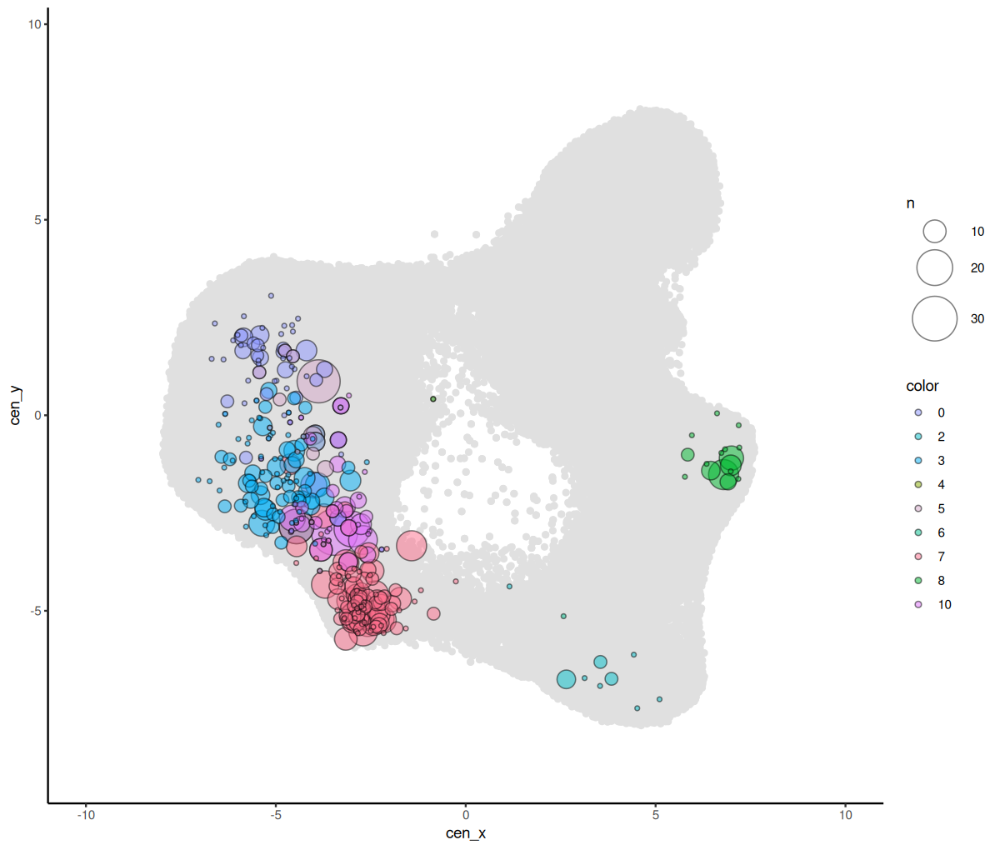

In [57]:
options(repr.plot.width = 10, repr.plot.height = 8.5)
ggplot() +
geom_point(data = clones_with_centroids, 
           aes(x = cen_x, y = cen_y), 
           color = "grey88", alpha = 1) +
new_scale("alpha") +
new_scale("size") +
geom_point(data = (clones_with_centroids  %>% dplyr::filter(n>4)), 
           aes(x = cen_x, y = cen_y, size = n, fill = color), alpha = 0.5, shape = 21) +
ylim(-9,9.5) +
xlim(-10,10) +
scale_fill_manual(values = gut_cdn@misc$col_pal) +
theme_bw() +
scale_size(range = c(1, 15)) +
theme_classic()


### CD

In [55]:
options(repr.plot.width = 15, repr.plot.height = 13)


Joining with `by = join_by(clone_aa)`
Joining with `by = join_by(clone_aa)`


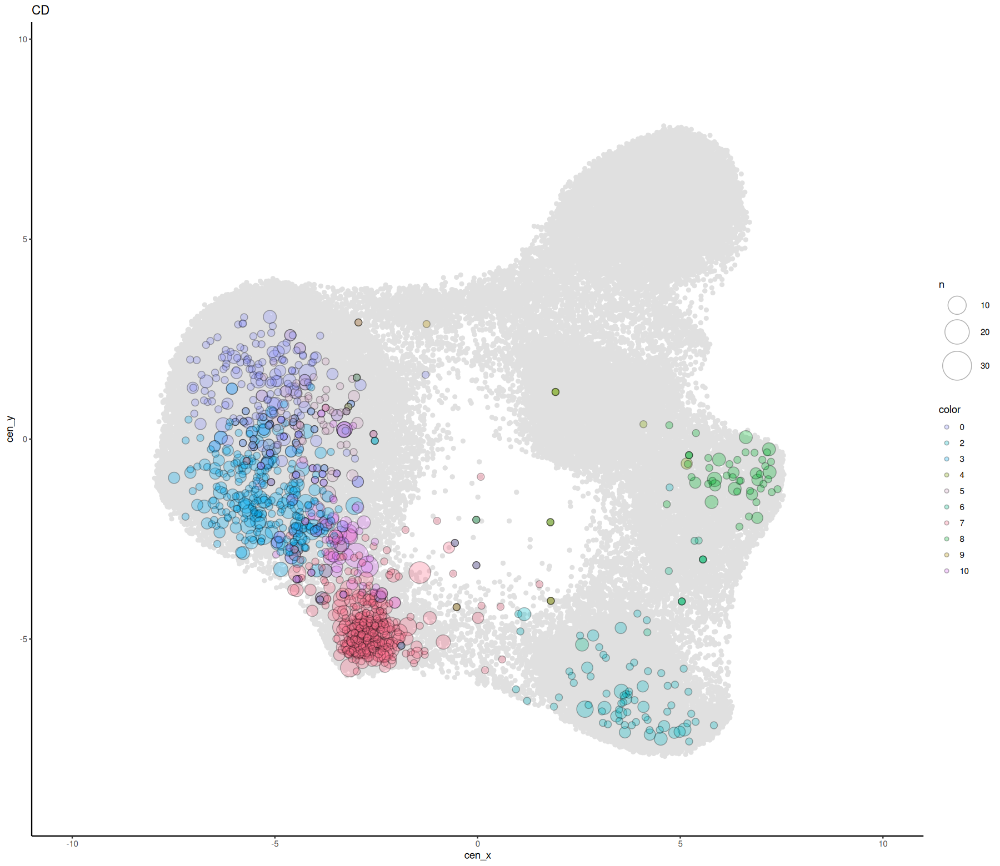

In [59]:
centroids  <- metadata_7  %>% 
dplyr::filter(diagnosis == "CD")  %>% 
group_by(clone_aa)  %>% summarise(cen_x = mean(umap_1), cen_y = mean(umap_2))

color  <- metadata_6  %>% 
dplyr::filter(diagnosis == "CD")  %>% 
group_by(clone_aa, integrated_snn_res.0.6)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(clone_aa)  %>% 
slice_max(order_by = n, n = 1)  %>% 
select(-n)

clones_with_centroids  <- metadata_6  %>% group_by(clone_aa)  %>% 
dplyr::filter(diagnosis == "CD")  %>% 
filter(!grepl(clone_aa, pattern = " NA"))  %>% 
tally  %>% 
arrange(desc(n))  %>% 
left_join(centroids)  %>% 
left_join(color)   

clones_with_centroids$color  <- clones_with_centroids$`integrated_snn_res.0.6`

ggplot() +
geom_point(data = clones_with_centroids, 
           aes(x = cen_x, y = cen_y), 
           color = "grey88", alpha = 1) +
new_scale("alpha") +
new_scale("size") +
geom_point(data = (clones_with_centroids  %>% dplyr::filter(n>2)), 
           aes(x = cen_x, y = cen_y, size = n, fill = color), alpha = 0.3, shape = 21) +
ylim(-9,9.5) +
xlim(-10,10) +
scale_fill_manual(values = gut_cdn@misc$col_pal) +
theme_bw() +
scale_size(range = c(3, 15), limits = c(3,35)) +
theme_classic() + ggtitle("CD")


### UC

Joining with `by = join_by(clone_aa)`
Joining with `by = join_by(clone_aa)`


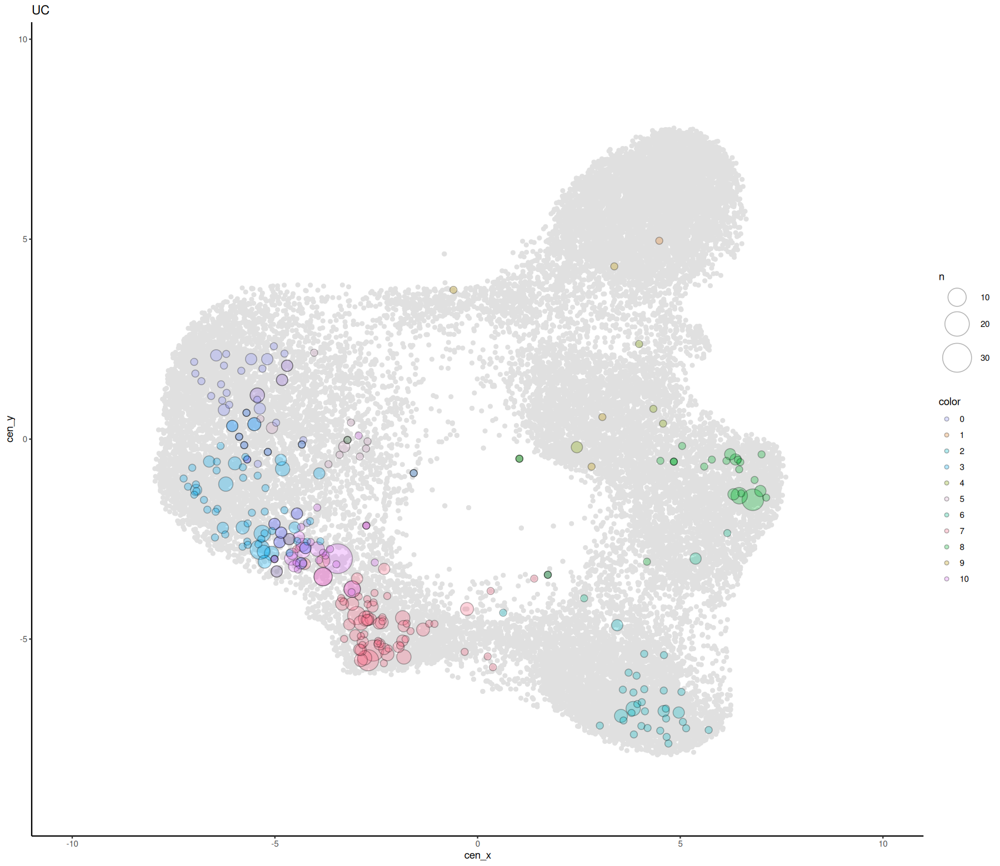

In [60]:
centroids  <- metadata_7  %>% 
dplyr::filter(diagnosis == "UC")  %>% 
group_by(clone_aa)  %>% summarise(cen_x = mean(umap_1), cen_y = mean(umap_2))

color  <- metadata_6  %>% 
dplyr::filter(diagnosis == "UC")  %>% 
group_by(clone_aa, integrated_snn_res.0.6)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(clone_aa)  %>% 
slice_max(order_by = n, n = 1)  %>% 
select(-n)

clones_with_centroids  <- metadata_6  %>% group_by(clone_aa)  %>% 
dplyr::filter(diagnosis == "UC")  %>% 
filter(!grepl(clone_aa, pattern = " NA"))  %>% 
tally  %>% 
arrange(desc(n))  %>% 
left_join(centroids)  %>% 
left_join(color)   

clones_with_centroids$color  <- clones_with_centroids$`integrated_snn_res.0.6`

ggplot() +
geom_point(data = clones_with_centroids, 
           aes(x = cen_x, y = cen_y), 
           color = "grey88", alpha = 1) +
new_scale("alpha") +
new_scale("size") +
geom_point(data = (clones_with_centroids  %>% dplyr::filter(n>2)), 
           aes(x = cen_x, y = cen_y, size = n, fill = color), alpha = 0.3, shape = 21) +
ylim(-9,9.5) +
xlim(-10,10) +
scale_fill_manual(values = gut_cdn@misc$col_pal) +
theme_bw() +
scale_size(range = c(3, 15), limits = c(3,35)) +
theme_classic() + ggtitle("UC")


In [ ]:
### FGID

Joining with `by = join_by(clone_aa)`
Joining with `by = join_by(clone_aa)`


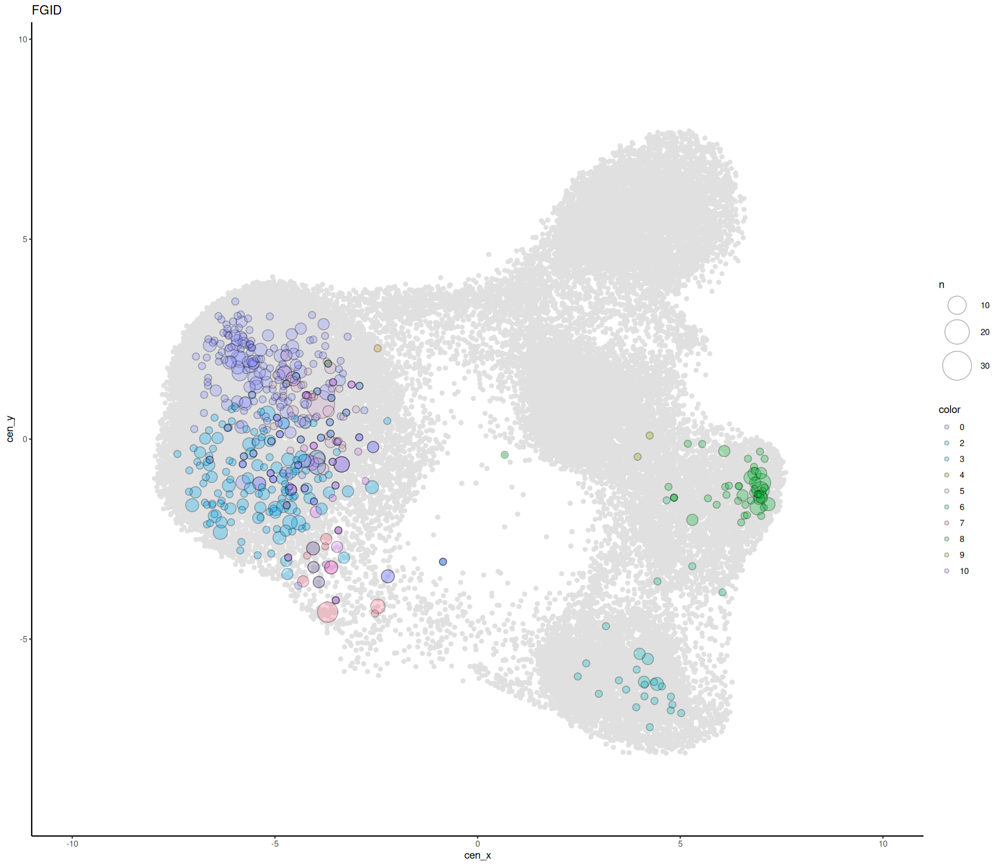

In [61]:
centroids  <- metadata_7  %>% 
dplyr::filter(diagnosis == "FGID")  %>% 
group_by(clone_aa)  %>% summarise(cen_x = mean(umap_1), cen_y = mean(umap_2))

color  <- metadata_6  %>% 
dplyr::filter(diagnosis == "FGID")  %>% 
group_by(clone_aa, integrated_snn_res.0.6)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(clone_aa)  %>% 
slice_max(order_by = n, n = 1)  %>% 
select(-n)

clones_with_centroids  <- metadata_6  %>% group_by(clone_aa)  %>% 
dplyr::filter(diagnosis == "FGID")  %>% 
filter(!grepl(clone_aa, pattern = " NA"))  %>% 
tally  %>% 
arrange(desc(n))  %>% 
left_join(centroids)  %>% 
left_join(color)   

clones_with_centroids$color  <- clones_with_centroids$`integrated_snn_res.0.6`

ggplot() +
geom_point(data = clones_with_centroids, 
           aes(x = cen_x, y = cen_y), 
           color = "grey88", alpha = 1) +
new_scale("alpha") +
new_scale("size") +
geom_point(data = (clones_with_centroids  %>% dplyr::filter(n>2)), 
           aes(x = cen_x, y = cen_y, size = n, fill = color), alpha = 0.3, shape = 21) +
ylim(-9,9.5) +
xlim(-10,10) +
scale_fill_manual(values = gut_cdn@misc$col_pal) +
theme_bw() +
scale_size(range = c(3, 15), limits = c(3,35)) +
theme_classic() + ggtitle("FGID")


In [ ]:
### HEA

Joining with `by = join_by(clone_aa)`
Joining with `by = join_by(clone_aa)`


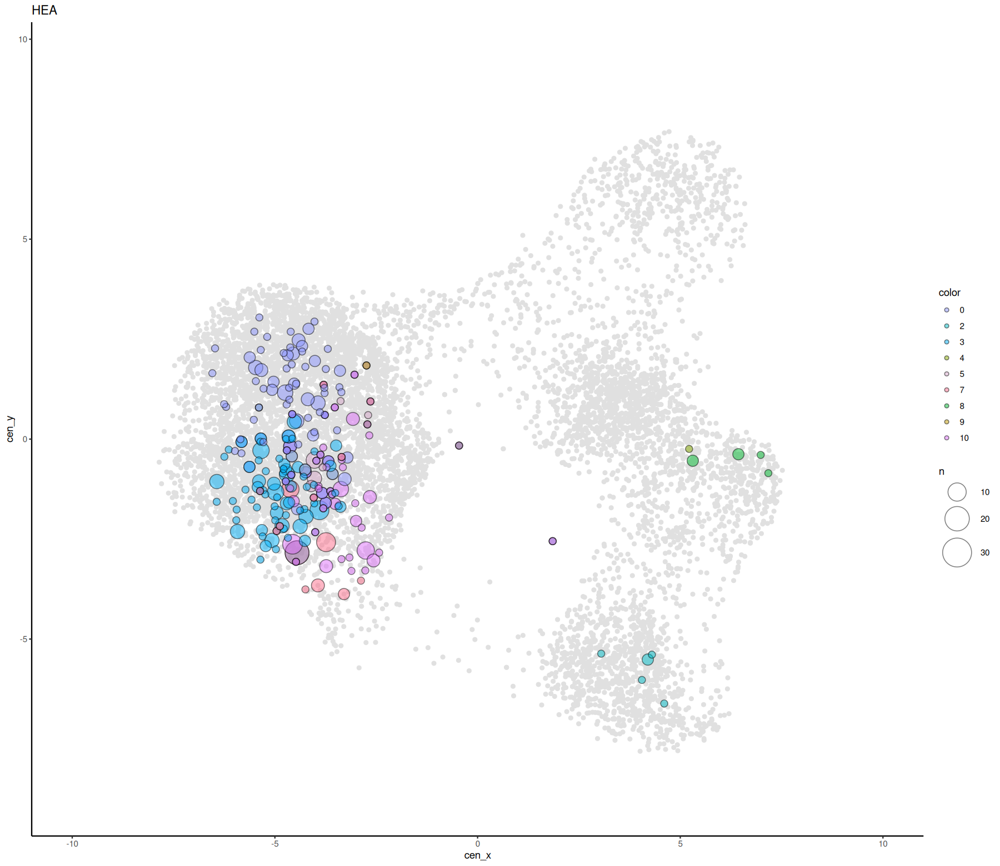

In [62]:
centroids  <- metadata_7  %>% 
dplyr::filter(diagnosis == "HEA")  %>% 
group_by(clone_aa)  %>% summarise(cen_x = mean(umap_1), cen_y = mean(umap_2))

color  <- metadata_6  %>% 
dplyr::filter(diagnosis == "HEA")  %>% 
group_by(clone_aa, integrated_snn_res.0.6)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(clone_aa)  %>% 
slice_max(order_by = n, n = 1)  %>% 
select(-n)

clones_with_centroids  <- metadata_6  %>% group_by(clone_aa)  %>% 
dplyr::filter(diagnosis == "HEA")  %>% 
filter(!grepl(clone_aa, pattern = " NA"))  %>% 
tally  %>% 
arrange(desc(n))  %>% 
left_join(centroids)  %>% 
left_join(color)   

clones_with_centroids$color  <- clones_with_centroids$`integrated_snn_res.0.6`

ggplot() +
geom_point(data = clones_with_centroids, 
           aes(x = cen_x, y = cen_y), 
           color = "grey88", alpha = 1) +
new_scale("alpha") +
new_scale("size") +
geom_point(data = (clones_with_centroids  %>% dplyr::filter(n>2)), 
           aes(x = cen_x, y = cen_y, size = n, fill = color), alpha = 0.5, shape = 21) +
ylim(-9,9.5) +
xlim(-10,10) +
scale_fill_manual(values = gut_cdn@misc$col_pal) +
theme_bw() +
scale_size(range = c(3, 15), limits = c(3,35)) +
theme_classic() + ggtitle("HEA")


## Clonal sharing between clusters heatmap

In [5]:
gut_cdn@meta.data <- gut_cdn@meta.data %>% mutate(
  clone_nt = paste(cdr3_B_nt,cdr3_A1_nt,cdr3_A2_nt),
  clone_aa = paste("CDR3b",cdr3_B,"CDR3a",cdr3_A1)
)

metadata_6 <- gut_cdn@meta.data

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b NA CDR3a NA,129380,0
CDR3b NA CDR3a CVVSDRGSTLGRLYF,92,0
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32,0
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28,0
CDR3b NA CDR3a CAVDWNYGQNFVF,24,0
CDR3b CSAPGQGSAYGYTF CDR3a NA,22,0
CDR3b NA CDR3a CAVMDSSYKLIF,21,0
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20,0
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19,0


In [7]:
clone_table  %>% dplyr::filter(!grepl(clone_aa, pattern = " NA"))

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32,0
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28,0
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20,0
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19,0
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,15,0
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15,0
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,14,0
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,14,0
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,14,0


In [8]:
more_than4_clones <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
    tally %>%
dplyr::filter(!grepl(clone_aa, pattern = "\\ NA"))  %>% 
    arrange(desc(n))   %>% dplyr::filter(n>4)

more_than4_clones

clone_aa,n
<chr>,<int>
CDR3b CASRLAGGPDTQYF CDR3a CAVSHGSSNTGKLIF,32
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,28
CDR3b CASSSTGRWRSTNTEAFF CDR3a CAVIGSGTYKYIF,20
CDR3b CASSTSGQSTDTQYF CDR3a CAVILNSGGYQKVTF,19
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,15
CDR3b CASSLGTGLSYNEQFF CDR3a CANTHGSSNTGKLIF,15
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,14
CDR3b CASSNQGSGNTIYF CDR3a CAEKAPSNTGKLIF,14
CDR3b CASSVEWRKDTEAFF CDR3a CAAFRDNFNKFYF,14


In [9]:
is_in_more_than4_clones  <- more_than4_clones  %>% pull(clone_aa)

In [12]:
metadata_6 %>%
  dplyr::group_by(clone_aa, seurat_clusters)  %>% 
    dplyr::filter(clone_aa %in% is_in_more_than4_clones)  %>% 
    tally()

clone_aa,seurat_clusters,n
<chr>,<fct>,<int>
CDR3b CAIGGLAGGKGTDTQYF CDR3a CAGGEAGNNRKLIW,6,1
CDR3b CAIGGLAGGKGTDTQYF CDR3a CAGGEAGNNRKLIW,11,11
CDR3b CAIHSTADTQYF CDR3a CALRRGNSGGSNYKLTF,8,4
CDR3b CAIHSTADTQYF CDR3a CALRRGNSGGSNYKLTF,9,1
CDR3b CAISDQRLGQFF CDR3a CVVNENNAGNMLTF,11,5
CDR3b CAISESGVTYNEQFF CDR3a CAEDNYGQNFVF,11,5
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,11,2
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,10,12
CDR3b CASGDRSTLTYEQYF CDR3a CAVNSQYSSASKIIF,11,10


In [11]:
metadata_6$annotations  %>% table

.
           Th1        Naive_1 Treg activated         Th17_1            Tcm 
         54392          51934          47505          44199          38339 
           Th2     Treg naive            CTL            Tfh        Naive_2 
         31992          19573          18771          17587          11276 
        Th17_2 
         10888 

In [13]:
clone_hm  <- metadata_6 %>%
  dplyr::group_by(clone_aa, seurat_clusters)  %>% 
    dplyr::filter(clone_aa %in% is_in_more_than4_clones)  %>% 
    tally()  %>% 
pivot_wider(names_from = seurat_clusters, values_from = n, values_fill = 0)

In [15]:
clone_hm_mtx  <- clone_hm  %>% column_to_rownames("clone_aa")  %>% 
as.matrix()

In [19]:
clone_hm_mtx

,6,11,8,9,10,7,4,2,5,3
CDR3b CAIGGLAGGKGTDTQYF CDR3a CAGGEAGNNRKLIW,1,11,0,0,0,0,0,0,0,0
CDR3b CAIHSTADTQYF CDR3a CALRRGNSGGSNYKLTF,0,0,4,1,0,0,0,0,0,0
CDR3b CAISDQRLGQFF CDR3a CVVNENNAGNMLTF,0,5,0,0,0,0,0,0,0,0
CDR3b CAISESGVTYNEQFF CDR3a CAEDNYGQNFVF,0,5,0,0,0,0,0,0,0,0
CDR3b CAISGSAGGQDTQYF CDR3a CAGQDYGGSQGNLIF,0,2,0,0,12,0,0,0,0,0
CDR3b CASGDRSTLTYEQYF CDR3a CAVNSQYSSASKIIF,0,10,0,0,0,0,0,0,0,0
CDR3b CASGFSSYEQYF CDR3a CATDAGTSGSRLTF,2,7,0,3,3,0,0,0,0,0
CDR3b CASGGLAGVTGELFF CDR3a CAGPTSGTYKYIF,0,8,0,0,0,0,0,0,0,0
CDR3b CASGGLSSGNTIYF CDR3a CAALYGGSQGNLIF,0,0,7,20,1,0,0,0,0,0
CDR3b CASGPTGTNQPQHF CDR3a CALGSNDYKLSF,0,5,0,0,0,0,0,0,0,0


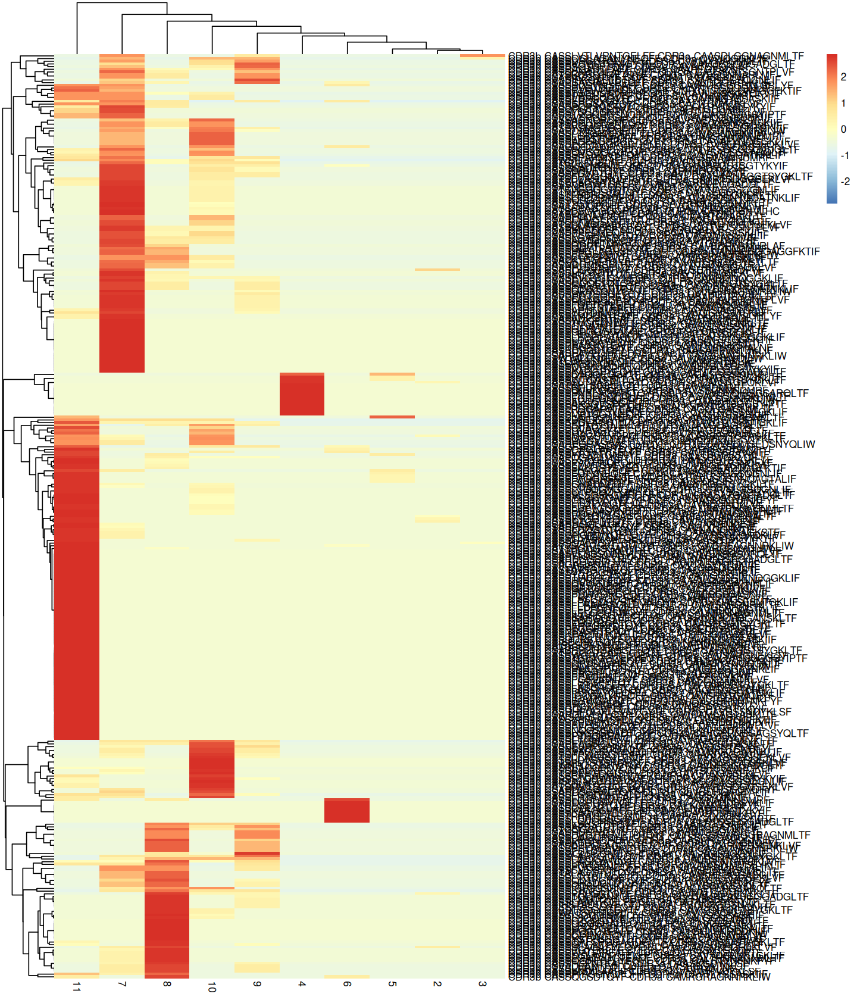

In [21]:
options(repr.plot.width = 12, repr.plot.height = 14)
pheatmap::pheatmap(clone_hm_mtx, scale = "row", cluster)

## TCR specificity IEDB pathogens

In [68]:
gut_output_iedb  <- read_delim("Files/TCR_analysis/gut5p_output_iedb.tsv", delim = "\t")

Rows: 16594 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (5): trimmed_input_sequence, match_sequence, epitope, antigen, organism
dbl (2): score, receptor_group

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [69]:
gut_output_iedb

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
SRRQGAYEQY,ARRQGAYEQY,0.991806,167063,YVLDHLIVV,Replication and transcription activator,Human herpesvirus 4 (Epstein Barr virus)
SSQGLNTGELF,ASSQGLNTGELF,0.971156,14414,GILGFVFTL,Matrix protein 1,Influenza A virus
SSQGLNTGELF,ASQGLNTGELF,0.992573,181607,"YYVGYLQPRTFLL,YLQPRTFLL","surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],surface glycoprotein [Severe acute respiratory syndrome coronavirus 2]","SARS-CoV2,SARS-CoV2"
SSQGLNTGELF,ASQGLNTGELF,0.992573,183499,YLQPRTFLL,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
SSQGLNTGELF,ASQGLNTGELF,0.992573,50218,KTWGQYWQV,Melanocyte protein PMEL,Homo sapiens (human)
SSQGLNTGELF,AAQGLNTGELF,0.976671,67805,YYVGYLQPRTFLL,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
SSQGLNTGELF,ATQGLNTGELF,0.978557,181745,YLQPRTFLL,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
SSPGTAYEQY,SVPGTAYEQY,0.971972,28222,FLGIYTVTVV,olfactory receptor 8D4 [Homo sapiens],Homo sapiens (human)
SSVRRVSGANVLT,ASTRRVSGANVLT,0.973097,134502,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2


In [71]:
gut_output_iedb$trimmed_input_sequence %in% gut_cdn$cdr3_B  %>% table

.
FALSE 
16594 

In [72]:
gut_cdn$cdr3_B %in% gut_output_iedb$trimmed_input_sequence  %>% table

.
 FALSE 
346456 

In [73]:
gut_input_seq  <- read_delim("data/tcrmatch/gut5p_tcrb.txt", delim = "/t", col_names = F)

Rows: 177185 Columns: 1
── Column specification ────────────────────────────────────────────────────────
Delimiter: "/t"
chr (1): X1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [74]:
gut_input_seq

X1
<chr>
ASSQGTGGRLGEQY
ARRTPAGGSNEQF
SSLQGLSSSYEQY
TSPTSGQGALYNEQF
SSLWGVSGNTIY
SSTGQENQPQH
SKGDNQETQY
SSLRQGRDTGELF
SSEGTGFANEKLF


In [75]:
## Need to trim cdr3_b sequence

In [76]:
gut_cdn$trimmed_input_sequence  <- substr(gut_cdn$cdr3_B,2,nchar(gut_cdn$cdr3_B)-1)

In [77]:
gut_cdn$trimmed_input_sequence %in% gut_output_iedb$trimmed_input_sequence  %>% table

.
 FALSE   TRUE 
346289    167 

In [78]:
gut_input_seq

X1
<chr>
ASSQGTGGRLGEQY
ARRTPAGGSNEQF
SSLQGLSSSYEQY
TSPTSGQGALYNEQF
SSLWGVSGNTIY
SSTGQENQPQH
SKGDNQETQY
SSLRQGRDTGELF
SSEGTGFANEKLF


In [79]:
gut_input_seq$X1  %in% gut_cdn$trimmed_input_sequence  %>% table

.
 FALSE   TRUE 
177001    184 

In [80]:
gut_cdn$trimmed_input_sequence %in% gut_input_seq$X1  %>% table

.
 FALSE   TRUE 
346185    271 

In [81]:
md_gut  <- gut_cdn@meta.data  %>% left_join(gut_output_iedb)

Joining with `by = join_by(trimmed_input_sequence)`
Warning message in left_join(., gut_output_iedb):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1893 of `x` matches multiple rows in `y`.
ℹ Row 14250 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


Need to correct that some sequences are duplicated. 

In [82]:
gut_output_iedb$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
11146  5448 

In [83]:
just_organism  <- gut_output_iedb  %>% dplyr::select(trimmed_input_sequence, organism)  %>% unique

In [84]:
just_organism$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
11146  3589 

3661 sequences are specific to multiple organisms

Let's filter the hits with the highest score for those. 

In [85]:
gut_output_iedb_noDupl  <- gut_output_iedb  %>% group_by(trimmed_input_sequence)  %>% 
slice_max(order_by = score, n = 1, with_ties = F)

In [98]:
gut_output_iedb_noDupl$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE 
11146 

In [99]:
gut_output_iedb_noDupl

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AAAENTEAF,SVAENTEAF,0.972497,145786,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAAGTEAF,ASAGTEAF,0.985209,203454,VMATRRNVL,Uncharacterized protein Rv1518/MT1568,Mycobacterium tuberculosis
AADQGSSYNEQF,SADQGSSYNEQF,0.992981,142975,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AADSSYNEQF,SADSSYNEQF,0.992564,177013,YVLDHLIVV,Replication and transcription activator,Human herpesvirus 4 (Epstein Barr virus)
AADSYEQY,ASDSYEQY,0.984311,67814,FLNGSCGSV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGDQETQY,ASGDQETQY,0.985339,146758,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGGAGEQF,ASGGAGEQF,0.986402,146874,SEHDYQIGGYTEKW,ORF3a protein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGGATNEKLF,ASGGATNEKLF,0.987405,37893,KLGGALQAK,55 kDa immediate-early protein 1,Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169))
AAGGETQY,SAGGETQY,0.991026,142881,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2


In [103]:
colnames(gut_cdn@meta.data)[c(138)]

[1] "match_sequence"

In [104]:
gut_cdn@meta.data$match_sequence  <- NULL
gut_cdn@meta.data$score  <- NULL
gut_cdn@meta.data$receptor_group  <- NULL
gut_cdn@meta.data$epitope  <- NULL
gut_cdn@meta.data$antigen  <- NULL
gut_cdn@meta.data$organism  <- NULL


In [105]:
md_gut  <- gut_cdn@meta.data  %>% left_join(gut_output_iedb_noDupl)

Joining with `by = join_by(trimmed_input_sequence)`


In [106]:
md_gut

orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,clone_abundance,log_clone_abundance,clone_abundance_group,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSQGTGGRLGEQY,NA,NA,NA,NA,NA,NA
SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,SARRTPAGGSNEQF,NA,NA,NA,NA,NA,NA
SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,2,1,2,ASSLQGLSSSYEQY,NA,NA,NA,NA,NA,NA
SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ATSPTSGQGALYNEQF,NA,NA,NA,NA,NA,NA
SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSLWGVSGNTIY,NA,NA,NA,NA,NA,NA
SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSTGQENQPQH,NA,NA,NA,NA,NA,NA
SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASKGDNQETQY,NA,NA,NA,NA,NA,NA
SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSLRQGRDTGELF,NA,NA,NA,NA,NA,NA
SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSEGTGFANEKLF,NA,NA,NA,NA,NA,NA


In [107]:
rownames(md_gut)  <- colnames(gut_cdn)

In [108]:
md_gut

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,clone_abundance,log_clone_abundance,clone_abundance_group,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSQGTGGRLGEQY,NA,NA,NA,NA,NA,NA
AAACCTGCAGTCACTA-1_1193610_1_1_1,SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,SARRTPAGGSNEQF,NA,NA,NA,NA,NA,NA
AAACCTGCATCGGACC-1_1193610_1_1_1,SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,2,1,2,ASSLQGLSSSYEQY,NA,NA,NA,NA,NA,NA
AAACCTGTCGCCAGCA-1_1193610_1_1_1,SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ATSPTSGQGALYNEQF,NA,NA,NA,NA,NA,NA
AAACCTGTCGCGATCG-1_1193610_1_1_1,SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSLWGVSGNTIY,NA,NA,NA,NA,NA,NA
AAACCTGTCTTCGGTC-1_1193610_1_1_1,SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSTGQENQPQH,NA,NA,NA,NA,NA,NA
AAACGGGAGCGTTTAC-1_1193610_1_1_1,SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASKGDNQETQY,NA,NA,NA,NA,NA,NA
AAACGGGCACAGACTT-1_1193610_1_1_1,SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSLRQGRDTGELF,NA,NA,NA,NA,NA,NA
AAACGGGCAGGTGCCT-1_1193610_1_1_1,SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,0,1,ASSEGTGFANEKLF,NA,NA,NA,NA,NA,NA


In [109]:
md_gut %>% group_by(organism)  %>% tally()

organism,n
<chr>,<int>
Hepatitis B virus (Human hepatitis B virus),1
"Homo sapiens (human),Homo sapiens (human)",2
Human herpesvirus 4 (Epstein Barr virus),7
"Human herpesvirus 4 (Epstein Barr virus),Human herpesvirus 4 (Epstein Barr virus)",1
"Human herpesvirus 4 (Epstein Barr virus),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169))",1
"Human herpesvirus 4 (Epstein Barr virus),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),SARS-CoV2",3
Human herpesvirus 4 strain B95-8 (Epstein-Barr virus (strain B95-8)),2
Human herpesvirus 5 (Human cytomegalovirus),6
"Human herpesvirus 5 (Human cytomegalovirus),SARS-CoV2",3


In [111]:
md_gut  %>% group_by(organism)  %>% tally  %>% arrange(desc(n))

organism,n
<chr>,<int>
NA,346290
SARS-CoV2,70
Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),16
"Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),SARS-CoV2",16
"SARS-CoV2,SARS-CoV2",8
Human herpesvirus 4 (Epstein Barr virus),7
Human herpesvirus 5 (Human cytomegalovirus),6
"Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 4 (Epstein Barr virus)",4
"Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),SARS-CoV2,SARS-CoV2,SARS-CoV2,SARS-CoV2,SARS-CoV2,SARS-CoV2",4


In [112]:
md_gut  <- md_gut  %>% separate(organism, into = c("organism2", NA, NA), sep = "\\(", remove = F)

Warning message:
“Expected 3 pieces. Additional pieces discarded in 28 rows [1893, 56866, 82201,
132544, 133794, 138405, 138694, 140318, 141417, 141578, 144146, 159290, 160707,
212343, 235180, 242810, 250817, 254603, 257854, 261536, ...].”
Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 112 rows [2471, 4002,
12074, 32162, 58137, 76164, 79628, 80649, 81573, 93925, 94716, 100892, 103206,
111694, 123997, 129875, 130651, 130829, 131807, 133773, ...].”


In [113]:
gut_cdn@meta.data  <- md_gut

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,log_clone_abundance,clone_abundance_group,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism,organism2
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASSQGTGGRLGEQY,NA,NA,NA,NA,NA,NA,NA
AAACCTGCAGTCACTA-1_1193610_1_1_1,SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,SARRTPAGGSNEQF,NA,NA,NA,NA,NA,NA,NA
AAACCTGCATCGGACC-1_1193610_1_1_1,SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,1,2,ASSLQGLSSSYEQY,NA,NA,NA,NA,NA,NA,NA
AAACCTGTCGCCAGCA-1_1193610_1_1_1,SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ATSPTSGQGALYNEQF,NA,NA,NA,NA,NA,NA,NA
AAACCTGTCGCGATCG-1_1193610_1_1_1,SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASSLWGVSGNTIY,NA,NA,NA,NA,NA,NA,NA
AAACCTGTCTTCGGTC-1_1193610_1_1_1,SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASSTGQENQPQH,NA,NA,NA,NA,NA,NA,NA
AAACGGGAGCGTTTAC-1_1193610_1_1_1,SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASKGDNQETQY,NA,NA,NA,NA,NA,NA,NA
AAACGGGCACAGACTT-1_1193610_1_1_1,SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASSLRQGRDTGELF,NA,NA,NA,NA,NA,NA,NA
AAACGGGCAGGTGCCT-1_1193610_1_1_1,SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,0,1,ASSEGTGFANEKLF,NA,NA,NA,NA,NA,NA,NA


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



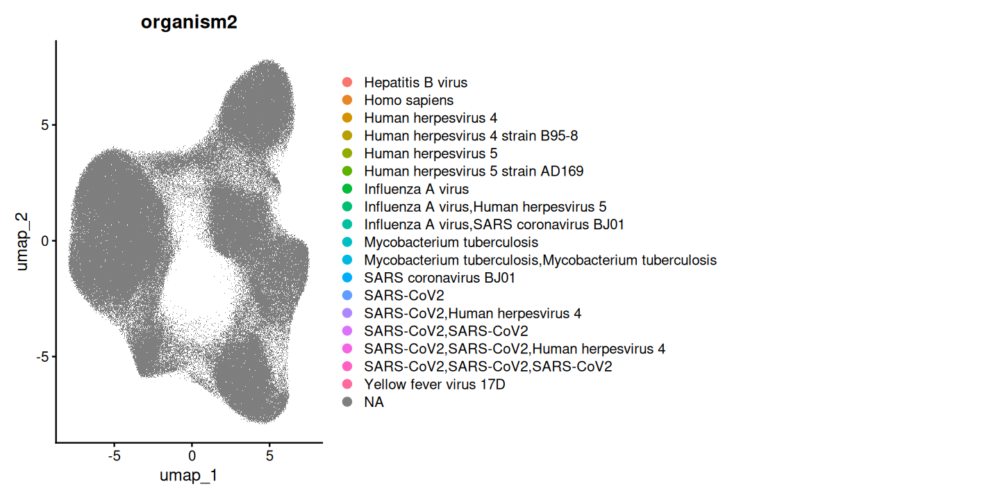

In [115]:
options(repr.plot.width = 12, repr.plot.height = 6)
DimPlot(gut_cdn, group.by = "organism2", ncol = 2)

In [ ]:
## filter only for score > 0.99

In [116]:
gut_output_iedb_noDupl  %>% dplyr::filter(score > 0.99)

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AADQGSSYNEQF,SADQGSSYNEQF,0.992981,142975,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AADSSYNEQF,SADSSYNEQF,0.992564,177013,YVLDHLIVV,Replication and transcription activator,Human herpesvirus 4 (Epstein Barr virus)
AAGGETQY,SAGGETQY,0.991026,142881,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGLAGGPYEQY,SAGLAGGPYEQY,0.992651,143011,YEDFLEYHDVRVVL,ORF8 protein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGQGIYEQY,SAGQGIYEQY,0.991848,143220,YTMADLVYAL,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AALGGDGETQY,SALGGDGETQY,0.992732,21306,"LPRRSGAAGA,TPRVTGGGAM,VTEHDTLLY","nucleoprotein,HCMVUL83,DNA processivity factor","Influenza A virus,Human herpesvirus 5 (Human cytomegalovirus),Human herpesvirus 5 (Human cytomegalovirus)"
AAPGQGTYEQY,SAPGQGTYEQY,0.991782,51160,KLGGALQAK,55 kDa immediate-early protein 1,Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169))
AAPLAGGPNEQF,SAPLAGGPNEQF,0.992315,58929,"LLWNGPMAV,LLWNGPMAV","non-structural protein NS4b,non-structural protein NS4b","Yellow fever virus 17D (Yellow fever virus (STRAIN 17D)),Yellow fever virus 17D (Yellow fever virus (STRAIN 17D))"
AARDRYNEQF,SARDRYNEQF,0.991714,142250,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2


In [117]:
high_score_seq  <- gut_output_iedb_noDupl  %>% dplyr::filter(score > 0.97)  %>% pull(trimmed_input_sequence)

In [118]:
gut_cdn@meta.data  <- gut_cdn@meta.data  %>% mutate(organism3 = if_else(trimmed_input_sequence %in% high_score_seq, organism2, NA_character_))

In [119]:
gut_cdn@meta.data  %>% group_by(organism2)  %>% tally()  %>% arrange(desc(n))

organism2,n
<chr>,<int>
NA,346290
SARS-CoV2,70
Human herpesvirus 5 strain AD169,43
Human herpesvirus 4,12
Human herpesvirus 5,9
"SARS-CoV2,SARS-CoV2",8
"SARS-CoV2,SARS-CoV2,SARS-CoV2",4
Influenza A virus,3
"Mycobacterium tuberculosis,Mycobacterium tuberculosis",3


In [123]:
gut_cdn$organism2  <- gsub(gut_cdn$organism2, pattern = "SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism2  <- gsub(gut_cdn$organism2, pattern = "SARS-CoV2,SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism2  <- gsub(gut_cdn$organism2, pattern = "SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism2  <- gsub(gut_cdn$organism2, pattern = "Human herpesvirus 5 strain AD169", replacement = "Human herpesvirus 5")

In [124]:
gut_cdn@meta.data  %>% group_by(organism2)  %>% tally()  %>% arrange(desc(n))

organism2,n
<chr>,<int>
NA,346290
SARS-CoV2,82
Human herpesvirus 5,52
Human herpesvirus 4,12
Influenza A virus,3
"Mycobacterium tuberculosis,Mycobacterium tuberculosis",3
"SARS-CoV2,Human herpesvirus 4",3
Homo sapiens,2
Human herpesvirus 4 strain B95-8,2


In [125]:
gut_cdn$organism4  <- ifelse(is.na(gut_cdn$organism3),"none",gut_cdn$organism3)

In [126]:
cols  <- scales::hue_pal() (length(levels(factor(gut_cdn$organism4))))

In [127]:
names(cols)  <- levels(factor(gut_cdn$organism4))

In [128]:
cols["none"]  <- "grey88"

In [129]:
cols

Hepatitis B virus  
                                            "#F8766D" 
                                        Homo sapiens  
                                            "#E9842C" 
                                 Human herpesvirus 4  
                                            "#D69100" 
                    Human herpesvirus 4 strain B95-8  
                                            "#BC9D00" 
                                 Human herpesvirus 5  
                                            "#9CA700" 
                    Human herpesvirus 5 strain AD169  
                                            "#6FB000" 
                                    Influenza A virus 
                                            "#00B813" 
               Influenza A virus,Human herpesvirus 5  
                                            "#00BD61" 
              Influenza A virus,SARS coronavirus BJ01 
                                            "#00C08E" 
                           Mycobacterium tuberculosis 
                                            "#00C0B4" 
Mycobacterium tuberculosis,Mycobacterium tuberculosis 
                                            "#00BDD4" 
                                                 none 
                                             "grey88" 
                                SARS coronavirus BJ01 
                                            "#00A7FF" 
                                            SARS-CoV2 
                                            "#7F96FF" 
                       SARS-CoV2,Human herpesvirus 4  
                                            "#BC81FF" 
                                  SARS-CoV2,SARS-CoV2 
                                            "#E26EF7" 
             SARS-CoV2,SARS-CoV2,Human herpesvirus 4  
                                            "#F763DF" 
                        SARS-CoV2,SARS-CoV2,SARS-CoV2 
                                            "#FF62BF" 
                              Yellow fever virus 17D  
                                            "#FF6A9A"

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



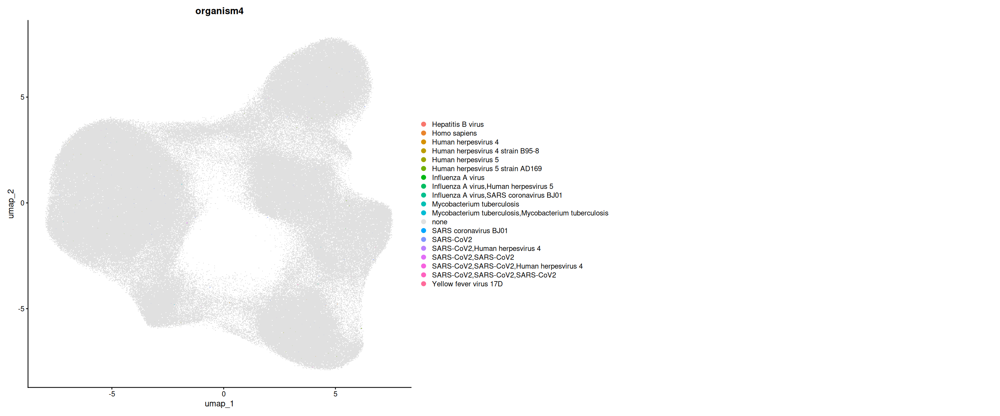

In [130]:
options(repr.plot.width = 24, repr.plot.height = 10)
DimPlot(gut_cdn, group.by = "organism4", ncol = 2, cols = cols)

In [131]:
gut_cdn@meta.data  %>% 
dplyr::filter(grepl(organism4, pattern = "SARS-CoV2") )  %>% 
group_by(annotations)  %>% 
tally()  %>% 
arrange(desc(n))

annotations,n
<fct>,<int>
Naive_1,14
Th2,12
Treg activated,11
Th1,10
Th17_1,9
Tcm,8
Tfh,6
Treg naive,5
CTL,5


In [132]:
gut_cdn@meta.data  %>% 
dplyr::filter(grepl(organism4, pattern = "herpesvirus 5") )  %>% 
group_by(annotations)  %>% 
tally()  %>% 
arrange(desc(n))

annotations,n
<fct>,<int>
Th1,16
Treg activated,9
Th17_1,7
Naive_1,5
Tcm,4
Th2,4
Treg naive,3
CTL,2
Tfh,2


In [133]:
gut_cdn@meta.data  %>% 
dplyr::filter(grepl(organism4, pattern = "herpesvirus 4") )  %>% 
group_by(annotations)  %>% 
tally()  %>% 
arrange(desc(n))

annotations,n
<fct>,<int>
Th1,7
Naive_1,4
Treg activated,3
Th17_1,1
Th2,1
CTL,1


In [138]:
gut_cdn@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism,organism2,organism3,organism4
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,SeuratProject,1984.128,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSQGTGGRLGEQY,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACCTGCAGTCACTA-1_1193610_1_1_1,SeuratProject,2306.014,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,SARRTPAGGSNEQF,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACCTGCATCGGACC-1_1193610_1_1_1,SeuratProject,1887.165,836,AAACCTGCATCGGACC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSLQGLSSSYEQY,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACCTGTCGCCAGCA-1_1193610_1_1_1,SeuratProject,2134.483,1068,AAACCTGTCGCCAGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ATSPTSGQGALYNEQF,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACCTGTCGCGATCG-1_1193610_1_1_1,SeuratProject,2163.869,1177,AAACCTGTCGCGATCG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSLWGVSGNTIY,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACCTGTCTTCGGTC-1_1193610_1_1_1,SeuratProject,1958.522,969,AAACCTGTCTTCGGTC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSTGQENQPQH,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACGGGAGCGTTTAC-1_1193610_1_1_1,SeuratProject,1681.969,699,AAACGGGAGCGTTTAC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASKGDNQETQY,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACGGGCACAGACTT-1_1193610_1_1_1,SeuratProject,2296.136,1268,AAACGGGCACAGACTT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSLRQGRDTGELF,NA,NA,NA,NA,NA,NA,NA,NA,none
AAACGGGCAGGTGCCT-1_1193610_1_1_1,SeuratProject,2114.526,988,AAACGGGCAGGTGCCT-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,ASSEGTGFANEKLF,NA,NA,NA,NA,NA,NA,NA,NA,none


In [141]:
gut_cdn$organism4  <- gsub(gut_cdn$organism4, pattern = "SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism4  <- gsub(gut_cdn$organism4, pattern = "SARS-CoV2,SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism4  <- gsub(gut_cdn$organism4, pattern = "SARS-CoV2,SARS-CoV2", replacement = "SARS-CoV2")
gut_cdn$organism4  <- gsub(gut_cdn$organism4, pattern = "Human herpesvirus 5 strain AD169", replacement = "Human herpesvirus 5")

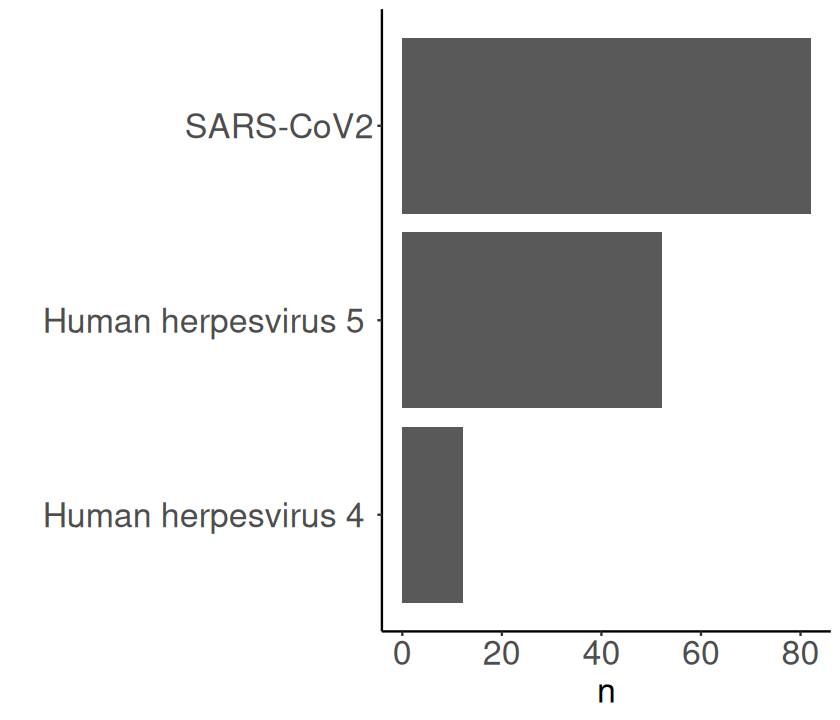

In [146]:
options(repr.plot.width = 7, repr.plot.height = 6)

gut_cdn@meta.data  %>% group_by(organism4)  %>% tally  %>% arrange(desc(n))  %>% 
dplyr::filter(organism4 != "none")  %>% 
dplyr::filter(n>5)  %>% 
ggplot(aes(x = reorder(organism4, X = n, FUN = max), y = n)) +
geom_bar(stat = "identity") +
coord_flip() +
ggtheme() +
xlab("") +
theme_classic() +
ggtheme()

In [148]:
ggsave("figures/tcr_specificity/iedb.svg", width = 12, height = 10, units = "cm", create.dir = TRUE)

✔ Created directory: figures/tcr_specificity.



In [149]:
gut_cdn@meta.data  <- gut_cdn@meta.data   %>% mutate(Sars_Cov2 = if_else(grepl(organism4, pattern = "SARS-CoV2"),"SARS-CoV2","Other"))  %>% 
mutate(CMV = if_else(grepl(organism4, pattern = "herpesvirus 5"),"CMV","Other"))  %>% 
mutate(EBV = if_else(grepl(organism4, pattern = "herpesvirus 4"), "EBV","Other"))   %>% 
mutate(Flu = if_else(grepl(organism4, pattern = "Influenza"), "Influenza A","Other"))

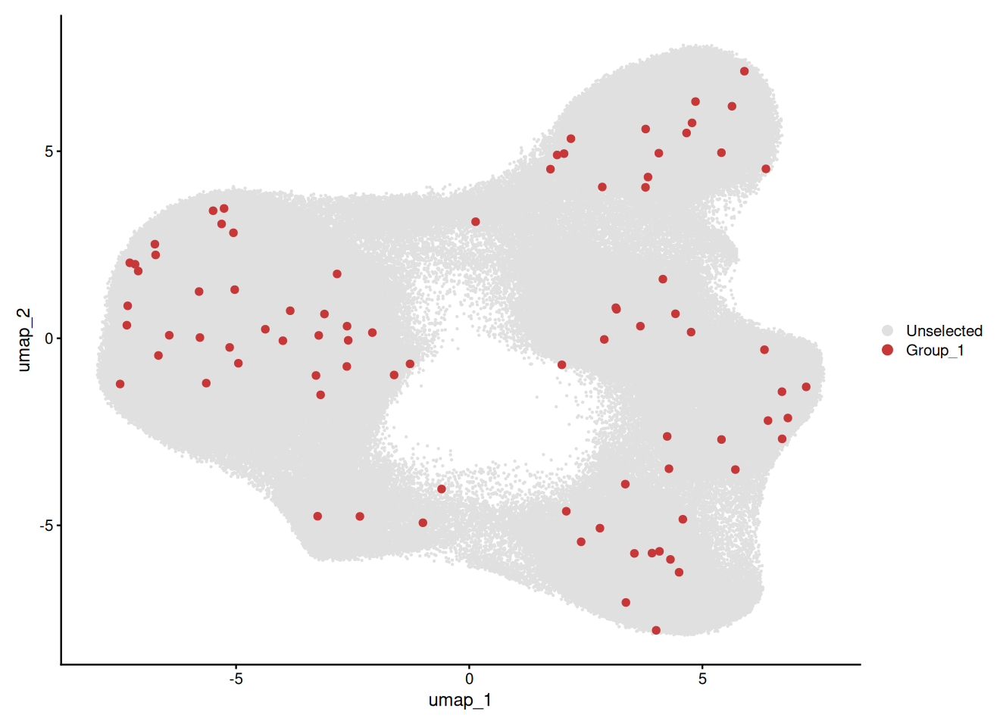

In [162]:
options(repr.plot.width = 10, repr.plot.height = 8)
DimPlot(gut_cdn,cells.highlight = colnames(subset(gut_cdn, Sars_Cov2 == "SARS-CoV2")),
        ncol = 2, order = "SARS-CoV2", raster = F, col = "grey88",
        cols.highlight = c("#c83737ff"), sizes.highlight = c(2,1))

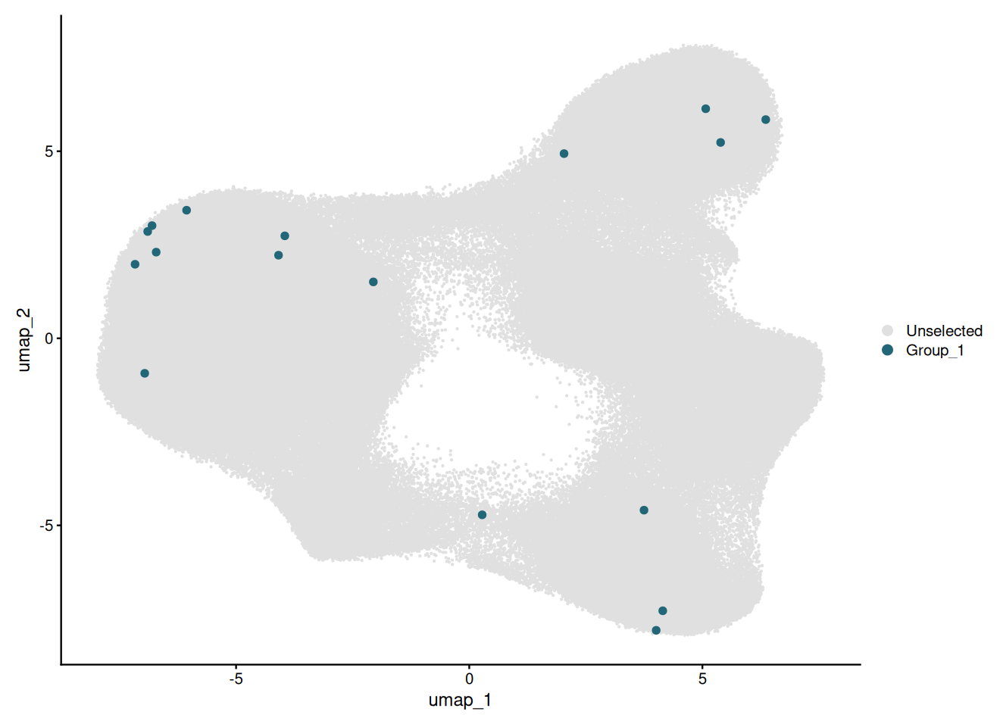

In [163]:
DimPlot(gut_cdn,cells.highlight = colnames(subset(gut_cdn, EBV == "EBV")),
        ncol = 2, order = "EBV", raster = F, col = "grey88",
        cols.highlight = c("#216778ff"), sizes.highlight = c(2,1))

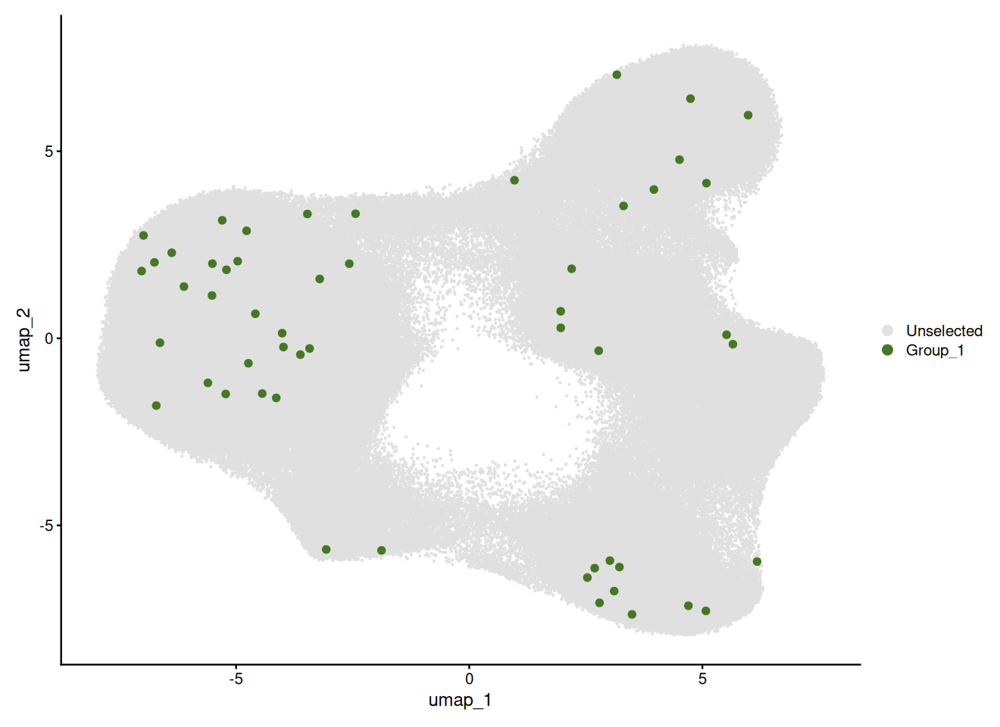

In [164]:
DimPlot(gut_cdn,cells.highlight = colnames(subset(gut_cdn, CMV == "CMV")),
        ncol = 2, order = "CMV", raster = F, col = "grey88",
        cols.highlight = c("#447821ff"), sizes.highlight = c(2,1))